# Hot Oceans Album: Warm Water and Tropical Cyclones

Issue #21. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md). Every source is listed in [data/hot_oceans/sources.md](../data/hot_oceans/sources.md).

EIC page [5097 2022 Hurricane Season](https://svs.gsfc.nasa.gov/5097/) draws a season of storm tracks over sea surface temperature and says that warm water makes and feeds hurricanes. This notebook checks that message in the data behind the page, for the four ocean basins the album plays (Atlantic, West Pacific, South Indian, South Pacific), and looks for what in it can become music:

1. **Where are storms born?** The sea surface temperature under each storm when it forms, against the 26.5 °C line EIC draws.
2. **Does warmer water make stronger storms?** How a storm's wind changes over the next 24 hours, against the water under it, and how each storm's energy relates to the water it crossed.
3. **What do high-energy storms look like?** Peak wind, lifetime, distance travelled, speed and rapid intensification of the most energetic storms against the rest.
4. **Are hot seasons stormier?** Each season's water temperature in the basin's main development region against the season's storm count and energy, and where 2023 sits.

5. **What can become music?** The findings above as sound, joined with the earlier single-storm design (wind speed as tempo, landfall as the big drum), and the storms that would make the clearest tracks.

**Years.** The storm-by-storm analysis (sections 4–7) uses eight years, 2003–2006 and 2021–2024: the first and last four of the MUR record that JTWC has published, about 500 named storms. The season comparison (section 8) uses every season from 2003 to 2024, but only the peak months of each basin. Each monthly map takes ERDDAP 30–60 seconds to cut, so this keeps the first run near an hour instead of three.

Run with `npm run notebook`. Downloads go to `data/hot_oceans/raw/` (local only). No login is needed. The first run downloads 194 monthly sea surface temperature maps (about 450 MB); reruns read the local files.

In [1]:
import html
import io
import json
import re
import zipfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display
from scipy.io import netcdf_file
from scipy.stats import spearmanr

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/hot_oceans/raw")
for sub in ("api", "jtwc", "mur_monthly"):
    (RAW / sub).mkdir(parents=True, exist_ok=True)

SVS_ID = 5097       # 2022 Hurricane Season: storm tracks over sea surface temperature
WIND_SVS_ID = 5072  # Atlantic Hurricane Wind Speed Plots: the season as wind speed over time
EIC_GALLERY = 40467
YEARS = (2003, 2024)  # MUR starts in June 2002; JTWC has not published 2025 yet
STORM_YEARS = (2003, 2004, 2005, 2006, 2021, 2022, 2023, 2024)  # storm-by-storm analysis (sections 4-7)
PEAK_MONTHS = (1, 2, 3, 7, 8, 9, 10)  # the basins' peak months, for the season comparison (section 8)
WARM_C = 26.5         # the threshold EIC names on 5097

HURDAT2_URL = "https://www.nhc.noaa.gov/data/hurdat/hurdat2-1851-2025-092326.txt"
JTWC_URL = "https://www.metoc.navy.mil/jtwc/products/best-tracks/{y}/{y}s-b{b}/b{b}{y}.zip"
ERDDAP = "https://coastwatch.pfeg.noaa.gov/erddap/griddap"
MUR_DATASET = "jplMURSST41mday"
MUR_URL = (f"{ERDDAP}/{MUR_DATASET}.nc?sst%5B({{y}}-{{m:02d}}-16T00:00:00Z)%5D"
           "%5B(-50):25:(55)%5D%5B(-179.99):25:(180)%5D")


def download(name, url, timeout=600):
    """Download url into data/hot_oceans/raw once and return the local path."""
    path = RAW / name
    if not path.exists():
        response = requests.get(url, timeout=timeout)
        response.raise_for_status()
        tmp = path.with_suffix(path.suffix + ".part")
        tmp.write_bytes(response.content)
        tmp.rename(path)
    return path


def svs_page(page_id):
    return json.loads(download(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", text or ""))).strip()


def source_note(fig, text):
    fig.text(0.01, -0.02, text, fontsize=8, color="gray", ha="left", va="top")


TRACK_CREDIT = "Tracks: NOAA NHC HURDAT2 (Atlantic), JTWC best tracks (other basins)."
SST_CREDIT = "SST: GHRSST MUR v4.1 monthly (NASA JPL), via NOAA CoastWatch ERDDAP."
CREDIT = TRACK_CREDIT + " " + SST_CREDIT
BASINS = ["Atlantic", "West Pacific", "South Indian", "South Pacific"]
BASIN_COLOR = {"Atlantic": "#e8785a", "West Pacific": "#4c8bd6", "South Indian": "#9a6fd0", "South Pacific": "#3aa58a"}

## 1. Links

Everything this notebook reads, in one place. The tables are built from the SVS API, so they stay correct if EIC changes.

### 1.1 Where the visualizations sit in the EIC gallery

In [2]:
def gallery_paths(gallery_id):
    """Map each page id to the gallery sections that lead to it from the EIC gallery."""
    paths = {}

    def walk(page_id, trail):
        page = svs_page(page_id)
        if page.get("page_type") != "Gallery":
            paths.setdefault(page_id, []).append(trail)
            return
        for group in page.get("media_groups", []):
            for item in group.get("items", []):
                inst = item.get("instance") or {}
                if item["type"] in ("gallery_page", "details_page") and inst.get("id"):
                    step = f"{group['title']} → [{inst.get('title')}]({inst['url'].replace('http://', 'https://')})"
                    if inst.get("page_type") == "Gallery" and inst["id"] not in [t[0] for t in trail]:
                        walk(inst["id"], trail + [(inst["id"], step)])
                    elif inst.get("page_type") != "Gallery":
                        paths.setdefault(inst["id"], []).append(trail + [(inst["id"], step)])

    walk(gallery_id, [])
    return paths


paths = gallery_paths(EIC_GALLERY)
rows = ["| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |", "| --- | --- |"]
for page_id in (SVS_ID, WIND_SVS_ID):
    trails = {" › ".join(step for _, step in trail) for trail in paths.get(page_id, [])}
    rows.append(f"| [{page_id}](https://svs.gsfc.nasa.gov/{page_id}/) | {'<br>'.join(sorted(trails))} |")
display(Markdown("\n".join(rows)))

| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |
| --- | --- |
| [5097](https://svs.gsfc.nasa.gov/5097/) | EIC Videos → [NASA and Hurricanes](https://svs.gsfc.nasa.gov/gallery/nasaand-hurricanes/) › Featured Visualizations → [2022 Hurricane Season](https://svs.gsfc.nasa.gov/5097/) |
| [5072](https://svs.gsfc.nasa.gov/5072/) | Daily Visualizations → [Daily Visualizations](https://svs.gsfc.nasa.gov/gallery/daily-visualizations/) › Visualizations → [Atlantic Hurricane Wind Speed Plots](https://svs.gsfc.nasa.gov/5072/) |

### 1.2 What the pages cite, and what this notebook downloads

- **Cited by EIC** comes from the `datasets` field of each SVS page, as published.
- **Downloaded here** is what this notebook actually reads.

In [3]:
JTWC_PAGE = "https://www.metoc.navy.mil/jtwc/jtwc.html?best-tracks"
DOWNLOADED = {
    "HURDAT2": (f"[HURDAT2]({HURDAT2_URL}) (NOAA NHC, revised 2026-09-23)",
                "The dataset 5072 cites. NHC's post-season best tracks, which replace the ATCF best tracks once a season is reviewed. Atlantic only. Public."),
    "Automated Tropical Cyclone Forecast (ATCF) - Best Track": (
        f"[JTWC best tracks]({JTWC_PAGE}), ATCF b-deck format: `{JTWC_URL.format(y='<year>', b='<wp|sh>')}`",
        "Substitute for the other basins. The NHC ATCF archive that EIC links covers only the Atlantic and the eastern and central Pacific; "
        "the US Joint Typhoon Warning Center keeps the ATCF best tracks of the West Pacific and the Southern Hemisphere. Public."),
    "Multi-scale Ultra-high Resolution (MUR) Sea Surface Temperature (SST) Analysis": (
        f"[MUR SST v4.1 monthly composite]({ERDDAP}/{MUR_DATASET}.html) on NOAA CoastWatch ERDDAP, every 25th grid point (0.25°), 50° S–55° N",
        "The dataset 5097 cites, served without a login by NOAA CoastWatch. ERDDAP averages the daily MUR v4.1 analysis into months. "
        "PO.DAAC's own copy needs an Earthdata login and is about 400 MB a day. Public."),
}
rows = ["| SVS page | Cited by EIC | Downloaded here | Note |", "| --- | --- | --- | --- |"]
for page_id in (SVS_ID, WIND_SVS_ID):
    page = svs_page(page_id)
    for d in page["datasets"]:
        name = d["name"] or d["common_name"]
        cited = f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link"
        used, note = DOWNLOADED.get(name, ("nothing", "Not about storm position, strength or water temperature. Not analyzed."))
        rows.append(f"| [{page_id}](https://svs.gsfc.nasa.gov/{page_id}/) | {cited} | {used} | {note} |")
display(Markdown("\n".join(rows)))

| SVS page | Cited by EIC | Downloaded here | Note |
| --- | --- | --- | --- |
| [5097](https://svs.gsfc.nasa.gov/5097/) | CPC (Climate Prediction Center) Cloud Composite, no link | nothing | Not about storm position, strength or water temperature. Not analyzed. |
| [5097](https://svs.gsfc.nasa.gov/5097/) | Multi-scale Ultra-high Resolution (MUR) Sea Surface Temperature (SST) Analysis, no link | [MUR SST v4.1 monthly composite](https://coastwatch.pfeg.noaa.gov/erddap/griddap/jplMURSST41mday.html) on NOAA CoastWatch ERDDAP, every 25th grid point (0.25°), 50° S–55° N | The dataset 5097 cites, served without a login by NOAA CoastWatch. ERDDAP averages the daily MUR v4.1 analysis into months. PO.DAAC's own copy needs an Earthdata login and is about 400 MB a day. Public. |
| [5097](https://svs.gsfc.nasa.gov/5097/) | [IMERG](https://pmm.nasa.gov/sites/default/files/document_files/IMERG_ATBD_V4.4.pdf) | nothing | Not about storm position, strength or water temperature. Not analyzed. |
| [5097](https://svs.gsfc.nasa.gov/5097/) | [Automated Tropical Cyclone Forecast (ATCF) - Best Track](https://ftp.nhc.noaa.gov/atcf/) | [JTWC best tracks](https://www.metoc.navy.mil/jtwc/jtwc.html?best-tracks), ATCF b-deck format: `https://www.metoc.navy.mil/jtwc/products/best-tracks/<year>/<year>s-b<wp|sh>/b<wp|sh><year>.zip` | Substitute for the other basins. The NHC ATCF archive that EIC links covers only the Atlantic and the eastern and central Pacific; the US Joint Typhoon Warning Center keeps the ATCF best tracks of the West Pacific and the Southern Hemisphere. Public. |
| [5072](https://svs.gsfc.nasa.gov/5072/) | HURDAT2, no link | [HURDAT2](https://www.nhc.noaa.gov/data/hurdat/hurdat2-1851-2025-092326.txt) (NOAA NHC, revised 2026-09-23) | The dataset 5072 cites. NHC's post-season best tracks, which replace the ATCF best tracks once a season is reviewed. Atlantic only. Public. |
| [5072](https://svs.gsfc.nasa.gov/5072/) | [Automated Tropical Cyclone Forecast (ATCF) - Best Track](https://ftp.nhc.noaa.gov/atcf/) | [JTWC best tracks](https://www.metoc.navy.mil/jtwc/jtwc.html?best-tracks), ATCF b-deck format: `https://www.metoc.navy.mil/jtwc/products/best-tracks/<year>/<year>s-b<wp|sh>/b<wp|sh><year>.zip` | Substitute for the other basins. The NHC ATCF archive that EIC links covers only the Atlantic and the eastern and central Pacific; the US Joint Typhoon Warning Center keeps the ATCF best tracks of the West Pacific and the Southern Hemisphere. Public. |

## 2. What EIC says

The captions of SVS 5097, quoted as published, and the description of the EIC gallery it sits in ([NASA and Hurricanes](https://svs.gsfc.nasa.gov/gallery/nasaand-hurricanes/), 40487).

In [4]:
captions = [plain(g.get("caption")) or plain(g.get("description")) for g in svs_page(SVS_ID)["media_groups"]]
gallery = plain(svs_page(40487)["description"])
display(Markdown("\n\n".join(f"> {c}" for c in captions if c) + f"\n\n**Gallery 40487:**\n\n> {gallery}"))

> 2022 Atlantic hurricane season.

> This visualization shows the hurricanes and tropical storms of 2022 as seen by NASA’s Integrated Multi-satellitE Retrievals for GPM (IMERG) - a data product combining precipitation observations from infrared and microwave satellite sensors united by the GPM Core Observatory. IMERG provides near real-time half-hourly precipitation estimates at ~10km resolution for the entire globe, helping researchers better understand Earth’s water cycle and extreme weather events, with applications for disaster management, tracking disease, resource management, energy production and food security. IMERG rain rates (in mm/hr) are laid under infrared cloud data from the NOAA Climate Prediction Center (CPC) Cloud Composite dataset together with storm tracks from the NOAA National Hurricane Center (NHC) Automated Tropical Cyclone Forecasting (ATCF) model. Sea surface temperatures (SST) are also shown over the oceans, derived from the NASA Multi-sensor Ultra-high Resolution (MUR) dataset, which combines data from multiple geostationary and orbiting satellites. Sea surface temperatures play an important role in hurricane formation and development, with warmer temperatures linked to more intense storms.

> 2022 Hurricane Season zoomed in to focus more on the Atlantic.

> Color bar for frozen precipitation rates (ie, snow rates). Shades of cyan represent low amounts of frozen precipitation, whereas shades of purple represent high amounts of precipitation.

> Color bar for liquid precipitation rates (ie, rain rates). Shades of green represent low amounts of liquid precipitation, whereas shades of red represent high amounts of precipitation.

> Sea Surface Temperature (SST) colorbar focusing primarily on temperatures between 20 degrees Celsius to 30 Celsius. Hurricanes tend to form over the warm tropical oceans where the SST is warmer than ~26.5 C (~80 F) depicted in colors from yellow to red.

**Gallery 40487:**

> Hurricanes are getting stronger due to climate change warming the air and oceans. NASA atmospheric scientist Mara Fuentes says NASA sees deep into hurricanes to better their power, track storms through the night, and precisely map flooding in real time. NASA shares this information with partners like NOAA for weather forecasts and FEME to support emergency responders. Before, during, and after a hurricane, NASA data is put to use by decision makers to make critical decisions.

**In short (our reading):**

- **The message**: warm water makes and feeds hurricanes. Two claims, in EIC's words: "Hurricanes tend to form over the warm tropical oceans where the SST is warmer than ~26.5 C (~80 F)", and "Sea surface temperatures play an important role in hurricane formation and development, with warmer temperatures linked to more intense storms." The page belongs to the SVS series *Hurricane-SST Connection*.
- **The picture**: one season of storm tracks drawn over the sea surface temperature, with the storm's category along each track.
- **The wider claim** (gallery 40487): "Hurricanes are getting stronger due to climate change warming the air and oceans."
- **What it does not say**: nothing about which way storms move or where they make landfall. The tracks show where storms went and how strong they were over which water.

This notebook checks the two claims of 5097, then looks at what the strongest storms look like and whether hot seasons are stormier. The last two are ours.

## 3. Source data

### 3.1 Storm tracks

[HURDAT2](https://www.nhc.noaa.gov/data/#hurdat) · [JTWC best tracks](https://www.metoc.navy.mil/jtwc/jtwc.html?best-tracks)

- **What it is**: the best estimate, made after each season, of every tropical cyclone's centre position, maximum sustained wind and minimum pressure, every 6 hours.
- **Provider**: NOAA National Hurricane Center (Atlantic), US Joint Typhoon Warning Center (West Pacific, South Indian, South Pacific). Both are US government works in the public domain.
- **Units**: degrees, knots (1-minute sustained wind, 1 kt = 1.852 km/h), hPa, UTC.

What we keep:

- **Basins**: the JTWC Southern Hemisphere file is split at 135° E by where each storm forms: west of it is the South Indian Ocean, east of it the South Pacific, as IBTrACS does.
- **Stages**: only the tropical and subtropical stages (`TD TS HU TY ST TC SD SS`). Extratropical, low and disturbance stages are dropped: they are no longer driven by warm water.
- **Times**: only the synoptic hours (00, 06, 12, 18 UTC), so that extra landfall fixes in HURDAT2 do not weigh more.
- **Storms**: those that reach 34 kt (named storms) and lie wholly within 2003–2024 (`rec_all`, for the season comparison). The storm-by-storm analysis keeps those whose every month has an SST map (`rec`, section 3.2).

In [5]:
TROPICAL = {"TD", "TS", "HU", "TY", "ST", "TC", "SD", "SS"}


def read_hurdat2(path):
    rows, sid, name = [], None, None
    for line in Path(path).read_text().splitlines():
        p = [s.strip() for s in line.split(",")]
        if p[0][:2].isalpha() and len(p) <= 4:  # header line of a storm
            sid, name = p[0], p[1]
            continue
        lat = float(p[4][:-1]) * (1 if p[4][-1] == "N" else -1)
        lon = float(p[5][:-1]) * (1 if p[5][-1] == "E" else -1)
        rows.append((sid, name, pd.Timestamp(f"{p[0]}T{p[1][:2]}:{p[1][2:]}"), p[3], lat, lon, int(p[6]), int(p[7]), "AL"))
    return pd.DataFrame(rows, columns=["sid", "name", "t", "stage", "lat", "lon", "vmax_kt", "mslp_hpa", "bb"])


def read_jtwc(path):
    """One ATCF b-deck zip of JTWC: one file per storm, one line per time and wind radius."""
    rows = []
    with zipfile.ZipFile(path) as z:
        for n in z.namelist():
            for line in z.read(n).decode("latin-1").splitlines():
                p = [s.strip() for s in line.split(",")]
                if len(p) < 11 or not p[2].isdigit():
                    continue
                try:
                    lat = float(p[6][:-1]) / 10 * (1 if p[6][-1] == "N" else -1)
                    lon = float(p[7][:-1]) / 10 * (1 if p[7][-1] == "E" else -1)
                    vmax = int(p[8])
                except ValueError:
                    continue
                mslp = int(p[9]) if p[9].isdigit() else np.nan
                name = p[27] if len(p) > 27 else ""  # recent files only
                rows.append((f"{p[0]}{p[1]}{Path(n).stem[-4:]}", name, pd.Timestamp(f"{p[2][:8]}T{p[2][8:10]}"), p[10],
                             lat, lon, vmax, mslp, p[0]))
    df = pd.DataFrame(rows, columns=["sid", "name", "t", "stage", "lat", "lon", "vmax_kt", "mslp_hpa", "bb"])
    return df.drop_duplicates(["sid", "t"])


hurdat = read_hurdat2(download(Path(HURDAT2_URL).name, HURDAT2_URL))
jtwc = pd.concat([read_jtwc(download(f"jtwc/b{b}{y}.zip", JTWC_URL.format(y=y, b=b)))
                  for y in range(YEARS[0], YEARS[1] + 1) for b in ("wp", "sh")])

first = jtwc.sort_values("t").groupby("sid").first()
basin_of = pd.Series(np.where(first["bb"] == "SH", np.where(first["lon"] % 360 < 135, "South Indian", "South Pacific"),
                              "West Pacific"), index=first.index)
jtwc["basin"] = jtwc["sid"].map(basin_of)
hurdat["basin"] = "Atlantic"

rec = pd.concat([hurdat, jtwc], ignore_index=True)
rec = rec[rec["t"].dt.hour.isin([0, 6, 12, 18]) & (rec["t"].dt.minute == 0) & rec["stage"].isin(TROPICAL)]
span = rec.groupby("sid")["t"].agg(["min", "max"])
inside = span.index[(span["min"].dt.year >= YEARS[0]) & (span["max"].dt.year <= YEARS[1])]
named = rec.groupby("sid")["vmax_kt"].max().loc[lambda v: v >= 34].index
rec_all = rec[rec["sid"].isin(inside.intersection(named))].sort_values(["sid", "t"]).reset_index(drop=True)
names = pd.concat([hurdat, jtwc])
names = names[~names["name"].isin(["", "INVEST"])].sort_values("t").groupby("sid")["name"].last()
rec_all["name"] = rec_all["sid"].map(names).fillna("")

MONTHS = pd.PeriodIndex(sorted({pd.Period(f"{y}-{m:02d}", "M") for y in range(YEARS[0], YEARS[1] + 1) for m in range(1, 13)
                                if y in STORM_YEARS or m in PEAK_MONTHS}))
covered = rec_all.groupby("sid")["t"].agg(lambda t: t.dt.to_period("M").isin(MONTHS).all() and t.dt.year.isin(STORM_YEARS).any())
rec = rec_all[rec_all["sid"].map(covered)].reset_index(drop=True)
pd.DataFrame({"storms 2003–2024": rec_all.groupby("basin")["sid"].nunique(),
              "storms analysed one by one": rec.groupby("basin")["sid"].nunique(),
              "their 6-hourly records": rec.groupby("basin").size()}).loc[BASINS]

,storms 2003–2024,storms analysed one by one,their 6-hourly records
basin,,,
Atlantic,367,142,3297
West Pacific,527,187,5080
South Indian,334,123,3838
South Pacific,186,65,1459


### 3.2 Sea surface temperature

[MUR SST v4.1](https://podaac.jpl.nasa.gov/dataset/MUR-JPL-L4-GLOB-v4.1) · [ERDDAP jplMURSST41mday](https://coastwatch.pfeg.noaa.gov/erddap/griddap/jplMURSST41mday.html)

- **What it is**: the Multi-scale Ultra-high Resolution analysis of the foundation sea surface temperature (the water just below the daily surface warming), from several satellites, on a 0.01° grid. 5097 draws it under the storms.
- **Provider**: NASA JPL (GHRSST), served as monthly means by NOAA CoastWatch ERDDAP.
- **What we download**: one map per month (every month of the eight storm years, the peak months of the others), every 25th grid point (0.25°), 50° S to 55° N. Land and sea ice are empty.
- **Units**: °C.

A monthly mean is enough to tell warm water from cool water under a storm, and smooths over the cold wake a storm leaves behind it. Section 5.1 checks that the result holds with the month before as well.

In [6]:
LAT0, LON0, STEP = -50.0, -179.99, 0.25
GRID_LAT = LAT0 + STEP * np.arange(421)
GRID_LON = LON0 + STEP * np.arange(1440)


def mur_path(month):
    return download(f"mur_monthly/mur_mday_{month.year}{month.month:02d}.nc", MUR_URL.format(y=month.year, m=month.month))


def read_mur(month):
    with netcdf_file(mur_path(month), "r", mmap=False) as f:
        sst = f.variables["sst"][0].astype("float32")
    sst[sst < -100] = np.nan
    return sst


for month in MONTHS:  # first run: about an hour
    mur_path(month)
print(f"{len(MONTHS)} monthly maps, {sum(mur_path(m).stat().st_size for m in MONTHS) / 1e6:.0f} MB")

194 monthly maps, 473 MB


### 3.3 The water under each storm

Each 6-hourly record gets the SST of the nearest grid cell in its month (`sst_c`) and in the month before (`sst_prev_c`). Records over land get none. Then, for every record, what the storm does next:

- `dv24_kt`: the change of maximum wind over the next 24 hours
- `speed_kmh`, `west_km`, `pole_km`: how fast and which way it moves over the next 24 hours (towards the west, and towards the pole of its own hemisphere)

In [7]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def sample_sst(sst, lat, lon):
    i = np.clip(np.rint((np.asarray(lat) - LAT0) / STEP).astype(int), 0, len(GRID_LAT) - 1)
    j = np.rint(((np.asarray(lon) - LON0) % 360) / STEP).astype(int) % len(GRID_LON)
    return sst[i, j]


def add_water(r):
    """SST under each record (this month and the month before) and what the storm does over the next 24 hours."""
    r = r.copy()
    r["sst_c"] = np.nan
    r["sst_prev_c"] = np.nan
    month_of = r["t"].dt.to_period("M")
    for month in MONTHS:
        if not ((month_of == month) | (month_of - 1 == month)).any():
            continue
        sst = read_mur(month)
        for col, m in (("sst_c", month_of), ("sst_prev_c", month_of - 1)):
            idx = r.index[m == month]
            r.loc[idx, col] = sample_sst(sst, r.loc[idx, "lat"], r.loc[idx, "lon"])
    g = r.groupby("sid")
    ahead = g[["t", "lat", "lon", "vmax_kt", "sst_c"]].shift(-4)
    whole_day = (ahead["t"] - r["t"]) == pd.Timedelta("24h")
    r["dv24_kt"] = (ahead["vmax_kt"] - r["vmax_kt"]).where(whole_day)
    r["sst_next24_c"] = ahead["sst_c"].where(whole_day)
    r["speed_kmh"] = (haversine_km(r["lat"], r["lon"], ahead["lat"], ahead["lon"]) / 24).where(whole_day)
    hemi = np.sign(r["lat"]).replace(0, 1)
    r["pole_km"] = ((ahead["lat"] - r["lat"]) * hemi * 111.2).where(whole_day)
    r["west_km"] = (-((ahead["lon"] - r["lon"] + 180) % 360 - 180) * 111.2 * np.cos(np.radians(r["lat"]))).where(whole_day)
    r["warm"] = r["sst_c"] >= WARM_C
    return r


rec = add_water(rec)
g = rec.groupby("sid")
print(f"records over water: {rec['sst_c'].notna().mean():.1%}")

records over water: 93.5%


### 3.4 Looking like 5097

The 2023 Atlantic season on the September 2023 SST, as 5097 draws 2022: the tracks over warm and cool water, the 26.5 °C line in white.

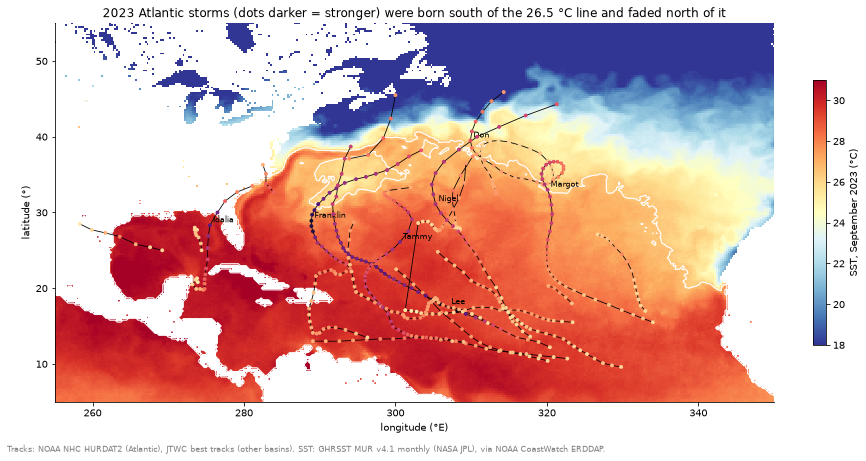

In [8]:
def sst_map(ax, month, lon_range, lat_range):
    sst = read_mur(pd.Period(month, "M"))
    lon360 = GRID_LON % 360
    order = np.argsort(lon360)
    im = ax.pcolormesh(lon360[order], GRID_LAT, sst[:, order], cmap="RdYlBu_r", vmin=18, vmax=31, shading="auto")
    ax.contour(lon360[order], GRID_LAT, np.nan_to_num(sst[:, order], nan=-5), levels=[WARM_C], colors="white", linewidths=1.2)
    ax.set(xlim=lon_range, ylim=lat_range, aspect="equal", xlabel="longitude (°E)", ylabel="latitude (°)")
    return im


CATEGORY_KT = [34, 64, 83, 96, 113, 137]  # tropical storm, categories 1-5 (Saffir-Simpson)
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
im = sst_map(ax, "2023-09", (255, 350), (5, 55))
for sid, d in rec[(rec["basin"] == "Atlantic") & (rec["t"].dt.year == 2023)].groupby("sid"):
    ax.plot(d["lon"] % 360, d["lat"], color="black", linewidth=0.8)
    ax.scatter(d["lon"] % 360, d["lat"], c=d["vmax_kt"], cmap="magma_r", vmin=20, vmax=140, s=8, zorder=3)
    if d["vmax_kt"].max() >= 64:
        top = d.loc[d["vmax_kt"].idxmax()]
        ax.annotate(top["name"].title(), (top["lon"] % 360, top["lat"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
fig.colorbar(im, ax=ax, shrink=0.7, label="SST, September 2023 (°C)")
ax.set_title("2023 Atlantic storms (dots darker = stronger) were born south of the 26.5 °C line and faded north of it")
source_note(fig, CREDIT)

## 4. Message 1: storms are born over warm water

> "Hurricanes tend to form over the warm tropical oceans where the SST is warmer than ~26.5 C (~80 F)" (5097)

The SST under the first record of each storm.

,storms,born at or above 26.5 °C,median SST (°C)
basin,,,
Atlantic,142,87%,28.4
West Pacific,187,100%,29.4
South Indian,123,99%,28.9
South Pacific,65,100%,29.4


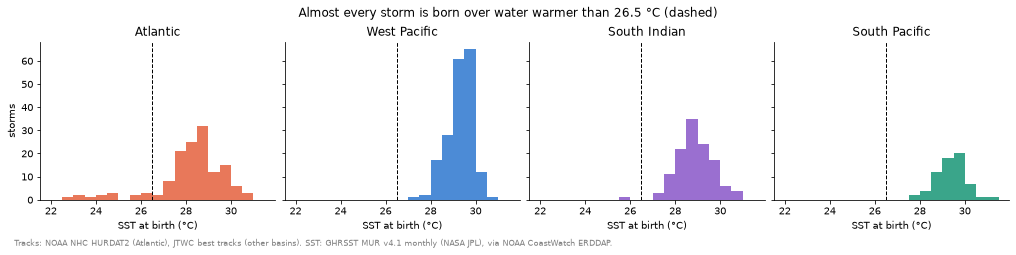

In [9]:
storms = g.agg(basin=("basin", "first"), name=("name", "first"), start=("t", "min"), end=("t", "max"),
               gen_lat=("lat", "first"), gen_lon=("lon", "first"), gen_sst=("sst_c", "first"),
               lmi_kt=("vmax_kt", "max"), min_mslp_hpa=("mslp_hpa", "min"))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharex=True, sharey=True, layout="constrained")
rows = []
for ax, b in zip(axes, BASINS):
    x = storms.loc[storms["basin"] == b, "gen_sst"].dropna()
    ax.hist(x, bins=np.arange(22, 32, 0.5), color=BASIN_COLOR[b])
    ax.axvline(WARM_C, color="black", linestyle="--", linewidth=1)
    ax.set(title=b, xlabel="SST at birth (°C)")
    rows.append({"basin": b, "storms": len(x), "born at or above 26.5 °C": f"{(x >= WARM_C).mean():.0%}", "median SST (°C)": round(x.median(), 1)})
axes[0].set_ylabel("storms")
fig.suptitle("Almost every storm is born over water warmer than 26.5 °C (dashed)")
source_note(fig, CREDIT)
pd.DataFrame(rows).set_index("basin")

## 5. Message 2: warmer water, stronger storms

> "Sea surface temperatures play an important role in hurricane formation and development, with warmer temperatures linked to more intense storms." (5097)

### 5.1 What the water under a storm says about its next 24 hours

For every record over water, the change of maximum wind over the next 24 hours, grouped by the SST under the storm. Records whose next 24 hours end over land are left out, so landfall does not count as weakening.

**The neutral SST**: where the mean 24-hour change turns from weakening to strengthening (°C)

,all records,latitude 10–25° only,SST of the month before
Atlantic,26.9,NaN,26.2
West Pacific,28.1,27.9,28.4
South Indian,27.5,27.6,27.4
South Pacific,28.1,28.1,28.0


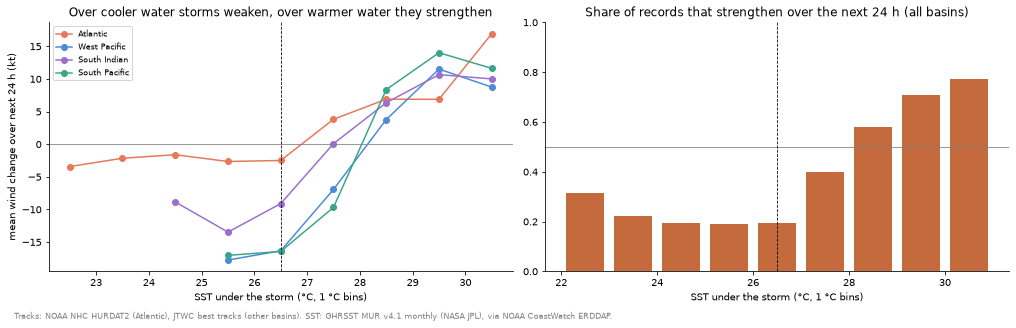

In [10]:
over_water = rec.dropna(subset=["dv24_kt", "sst_c", "sst_next24_c"])
SST_BINS = np.arange(21, 32, 1.0)


def by_sst(d, col="sst_c"):
    """Mean 24-hour wind change and share strengthening per 1 °C of SST, for bins with 30 records or more."""
    b = pd.cut(d[col], SST_BINS)
    out = d.groupby(b, observed=True)["dv24_kt"].agg(records="size", mean_kt="mean", strengthening=lambda v: (v > 0).mean())
    out.index = [i.mid for i in out.index]
    return out[out["records"] >= 30]


def neutral_sst(d):
    """The SST at which the mean 24-hour change crosses zero, by linear interpolation between 0.5 °C bins."""
    b = pd.cut(d["sst_c"], np.arange(22, 31.5, 0.5))
    m = d.groupby(b, observed=True)["dv24_kt"].agg(["mean", "size"])
    m = m[m["size"] >= 30]
    mids = np.array([i.mid for i in m.index])
    up = np.flatnonzero((m["mean"].values[:-1] < 0) & (m["mean"].values[1:] >= 0))
    if not len(up):
        return np.nan
    k = up[-1]
    y0, y1 = m["mean"].values[k], m["mean"].values[k + 1]
    return mids[k] + (mids[k + 1] - mids[k]) * (-y0) / (y1 - y0)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
for b in BASINS:
    t = by_sst(over_water[over_water["basin"] == b])
    axes[0].plot(t.index, t["mean_kt"], marker="o", color=BASIN_COLOR[b], label=b)
all_t = by_sst(over_water)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].axvline(WARM_C, color="black", linestyle="--", linewidth=0.8)
axes[0].set(title="Over cooler water storms weaken, over warmer water they strengthen", xlabel="SST under the storm (°C, 1 °C bins)",
            ylabel="mean wind change over next 24 h (kt)")
axes[0].legend(fontsize=8)
axes[1].bar(all_t.index, all_t["strengthening"], width=0.8, color="#c46a3c")
axes[1].axhline(0.5, color="gray", linewidth=0.8)
axes[1].axvline(WARM_C, color="black", linestyle="--", linewidth=0.8)
axes[1].set(title="Share of records that strengthen over the next 24 h (all basins)", xlabel="SST under the storm (°C, 1 °C bins)", ylim=(0, 1))
source_note(fig, CREDIT)

checks = pd.DataFrame({
    "all records": {b: neutral_sst(over_water[over_water["basin"] == b]) for b in BASINS},
    "latitude 10–25° only": {b: neutral_sst(over_water[(over_water["basin"] == b) & over_water["lat"].abs().between(10, 25)]) for b in BASINS},
    "SST of the month before": {b: neutral_sst(over_water[over_water["basin"] == b].assign(sst_c=lambda d: d["sst_prev_c"])) for b in BASINS},
}).round(1)
display(Markdown("**The neutral SST**: where the mean 24-hour change turns from weakening to strengthening (°C)"))
checks

### 5.2 When does the wind answer the water?

Does the SST under a storm tell about the wind change to come, or about the change around it now? The correlation between the SST under the storm and its 24-hour wind change, with the 24-hour window shifted from 48 hours before to 72 hours after. A shift of −12 h is the window centred on the moment of the SST.

,hours,rho,n
basin,,,
Atlantic,-18,0.26,2480
West Pacific,-18,0.40,4073
South Indian,-18,0.38,3068
South Pacific,-18,0.49,1120


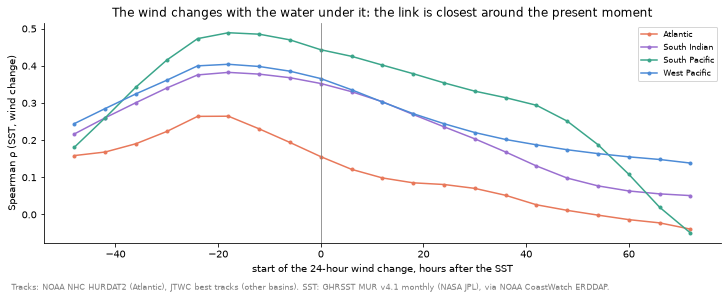

In [11]:
def lagged(rec, hours):
    """Spearman correlation between SST at t and the wind change from t + hours to t + hours + 24 h."""
    k = hours // 6
    g = rec.groupby("sid")
    v0, v1 = g["vmax_kt"].shift(-k), g["vmax_kt"].shift(-k - 4)
    t0, t1 = g["t"].shift(-k), g["t"].shift(-k - 4)
    ok = ((t0 - rec["t"]) == pd.Timedelta(hours=hours)) & ((t1 - t0) == pd.Timedelta("24h"))
    d = pd.DataFrame({"sst": rec["sst_c"], "dv": (v1 - v0)})[ok].dropna()
    return spearmanr(d["sst"], d["dv"]).statistic, len(d)


LAGS = list(range(-48, 73, 6))
lag = pd.DataFrame([(b, h, *lagged(rec[rec["basin"] == b], h)) for b in BASINS for h in LAGS], columns=["basin", "hours", "rho", "n"])
fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
for b, d in lag.groupby("basin"):
    ax.plot(d["hours"], d["rho"], marker=".", color=BASIN_COLOR[b], label=b)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(title="The wind changes with the water under it: the link is closest around the present moment", xlabel="start of the 24-hour wind change, hours after the SST",
       ylabel="Spearman ρ (SST, wind change)")
ax.legend(fontsize=8)
source_note(fig, CREDIT)
lag.loc[lag.groupby("basin")["rho"].idxmax()].set_index("basin").loc[BASINS].round(2)

### 5.3 Fuel: hours over warm water

Per storm. Does the water at birth, the average water under the track, or the time spent over warm water go with how strong and how energetic a storm gets?

- **Energy** is the accumulated cyclone energy (ACE): the sum of the squared maximum wind (kt²) of every 6-hourly record at 35 kt or more, divided by 10⁴. It grows with both strength and lifetime.
- **Warm hours**: hours at tropical storm strength (34 kt) or more over water at or above 26.5 °C. A storm that lives longer has more of them, so the **share** of its named life over warm water is shown as well.

In [12]:
rec["ace"] = np.where(rec["vmax_kt"] >= 35, rec["vmax_kt"] ** 2 / 1e4, 0.0)
g = rec.groupby("sid")
named_rec = rec[rec["vmax_kt"] >= 34]
step = haversine_km(g["lat"].shift(), g["lon"].shift(), rec["lat"], rec["lon"]).where((rec["t"] - g["t"].shift()) == pd.Timedelta("6h"))
storms = storms.assign(
    ace=g["ace"].sum(),
    life_days=(storms["end"] - storms["start"]).dt.total_seconds() / 86400,
    ts_days=named_rec.groupby("sid").size() * 0.25,
    track_km=step.groupby(rec["sid"]).sum(),
    max_dv24_kt=g["dv24_kt"].max(),
    track_sst=named_rec.groupby("sid")["sst_c"].mean(),
    warm_hours=named_rec[named_rec["warm"]].groupby("sid").size().reindex(storms.index, fill_value=0) * 6,
    abs_gen_lat=storms["gen_lat"].abs(),
)
storms["warm_share"] = storms["warm_hours"] / (storms["ts_days"] * 24)
storms["speed_kmh"] = storms["track_km"] / (storms["life_days"] * 24)
storms["season"] = np.where(storms["basin"].str.startswith("South") & (storms["start"].dt.month >= 7),
                            storms["start"].dt.year + 1, storms["start"].dt.year)

DRIVERS = {"gen_sst": "SST at birth", "track_sst": "mean SST under the track", "warm_hours": "hours over warm water",
           "warm_share": "share of its named life over warm water", "abs_gen_lat": "latitude of birth"}
OUTCOMES = {"lmi_kt": "peak wind", "ace": "energy (ACE)", "ts_days": "days as a named storm", "track_km": "distance travelled",
            "speed_kmh": "mean forward speed", "max_dv24_kt": "fastest 24-h strengthening"}
corr = pd.DataFrame({DRIVERS[x]: {OUTCOMES[y]: spearmanr(storms[x], storms[y], nan_policy="omit").statistic for y in OUTCOMES}
                     for x in DRIVERS}).round(2)
display(Markdown(f"**Spearman ρ, {len(storms)} storms** (rows: what the storm did; columns: what it had)"))
corr

**Spearman ρ, 517 storms** (rows: what the storm did; columns: what it had)

,SST at birth,mean SST under the track,hours over warm water,share of its named life over warm water,latitude of birth
peak wind,0.12,-0.02,0.78,-0.18,-0.22
energy (ACE),0.06,-0.08,0.88,-0.15,-0.25
days as a named storm,-0.01,-0.11,0.91,-0.13,-0.26
distance travelled,-0.02,-0.14,0.74,-0.10,-0.31
mean forward speed,-0.05,-0.18,-0.10,-0.20,0.17
fastest 24-h strengthening,0.19,0.02,0.68,-0.16,-0.22


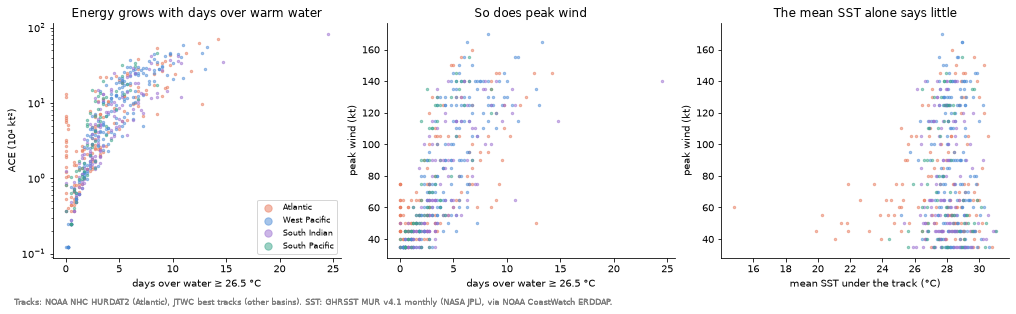

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for b in BASINS:
    d = storms[storms["basin"] == b]
    axes[0].scatter(d["warm_hours"] / 24, d["ace"], s=6, alpha=0.5, color=BASIN_COLOR[b], label=b)
    axes[1].scatter(d["warm_hours"] / 24, d["lmi_kt"], s=6, alpha=0.5, color=BASIN_COLOR[b])
    axes[2].scatter(d["track_sst"], d["lmi_kt"], s=6, alpha=0.5, color=BASIN_COLOR[b])
axes[0].set(yscale="log", xlabel="days over water ≥ 26.5 °C", ylabel="ACE (10⁴ kt²)", title="Energy grows with days over warm water")
axes[1].set(xlabel="days over water ≥ 26.5 °C", ylabel="peak wind (kt)", title="So does peak wind")
axes[2].set(xlabel="mean SST under the track (°C)", ylabel="peak wind (kt)", title="The mean SST alone says little")
axes[0].legend(fontsize=8, markerscale=3)
for ax in axes:
    source_note(fig, CREDIT)

### 5.4 Birth or path?

Is it the water where a storm is born that decides how strong it gets, or the water it meets along its path, and how that water changes? Two tests, each comparing how much of a storm's behaviour the birth water explains against the path water.

- **Each storm** (target: peak wind, and energy as log ACE). *Birth*: SST at birth, with the birth latitude and basin as context. *Path*: what the storm met from birth to its peak, so nothing after the peak is used: the mean SST under it, the hours over water ≥ 26.5 °C, and the change of SST from birth to the peak.
- **Each 6-hour step** (target: the wind change over the next 24 hours). *Birth*: the SST at the storm's birth. *Path*: the SST under it now and how it changes over those 24 hours. The wind now is in every model, since a storm near its peak has less room to grow.

The score is the cross-validated R²: the share of the variation a linear model explains in storms it was not fitted on (five folds, split by storm).

,peak wind,energy (log ACE)
birth SST,0.01,0.00
birth SST + latitude + basin,0.07,0.08
path to peak: mean SST and its change,0.01,-0.01
path to peak: + hours over warm water,0.29,0.40
hours from birth to peak only,0.23,0.34
hours to peak + share of them over warm water,0.22,0.32
birth + path,0.31,0.43


,24-h wind change
wind now only,0.115
+ birth SST,0.119
+ SST now,0.194
+ SST now and its change ahead,0.211
"+ birth, SST now and its change",0.227


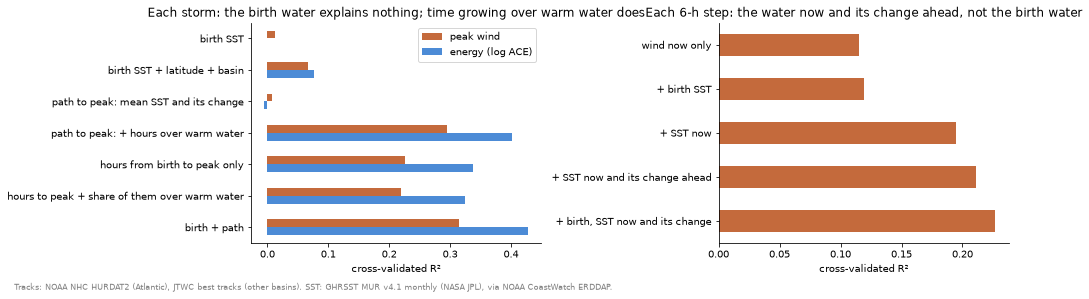

In [14]:
import zlib


def cv_r2(d, features, target, folds=5):
    """Out-of-fold R² of a linear least-squares fit, folds split by storm."""
    d = d.dropna(subset=features + [target])
    X = pd.get_dummies(d[features], columns=[c for c in features if not pd.api.types.is_numeric_dtype(d[c])], drop_first=True, dtype=float)
    X = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    y = d[target].to_numpy(dtype=float)
    fold = d["sid"].map(lambda s: zlib.crc32(s.encode()) % folds).to_numpy()  # the same split on every run
    pred = np.empty_like(y)
    for k in range(folds):
        coef = np.linalg.lstsq(X[fold != k], y[fold != k], rcond=None)[0]
        pred[fold == k] = X[fold == k] @ coef
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()


# Storm by storm: the path from birth to peak
peak_time = rec.loc[g["vmax_kt"].idxmax()].set_index("sid")["t"]
before_peak = rec[rec["t"] <= rec["sid"].map(peak_time)]
bp = before_peak.groupby("sid")
storms = storms.assign(
    path_sst=bp["sst_c"].mean(),
    path_warm_hours=before_peak[before_peak["warm"]].groupby("sid").size().reindex(storms.index, fill_value=0) * 6,
    path_sst_change=bp["sst_c"].last() - bp["sst_c"].first(),
    path_hours=(bp["t"].max() - bp["t"].min()).dt.total_seconds() / 3600,
    log_ace=np.log1p(storms["ace"]),
)
storms["path_warm_share"] = storms["path_warm_hours"] / storms["path_hours"].where(storms["path_hours"] > 0)
s_ = storms.reset_index()
STORM_MODELS = {
    "birth SST": ["gen_sst"],
    "birth SST + latitude + basin": ["gen_sst", "abs_gen_lat", "basin"],
    "path to peak: mean SST and its change": ["path_sst", "path_sst_change"],
    "path to peak: + hours over warm water": ["path_sst", "path_sst_change", "path_warm_hours"],
    "hours from birth to peak only": ["path_hours"],
    "hours to peak + share of them over warm water": ["path_hours", "path_warm_share"],
    "birth + path": ["gen_sst", "abs_gen_lat", "basin", "path_sst", "path_warm_hours", "path_sst_change"],
}
storm_scores = pd.DataFrame({m: {"peak wind": cv_r2(s_, f, "lmi_kt"), "energy (log ACE)": cv_r2(s_, f, "log_ace")}
                             for m, f in STORM_MODELS.items()}).T

# Step by step: the next 24 hours
steps = over_water.assign(gen_sst=over_water["sid"].map(storms["gen_sst"]),
                          sst_change24=over_water["sst_next24_c"] - over_water["sst_c"])
STEP_MODELS = {
    "wind now only": ["vmax_kt"],
    "+ birth SST": ["vmax_kt", "gen_sst"],
    "+ SST now": ["vmax_kt", "sst_c"],
    "+ SST now and its change ahead": ["vmax_kt", "sst_c", "sst_change24"],
    "+ birth, SST now and its change": ["vmax_kt", "gen_sst", "sst_c", "sst_change24"],
}
step_scores = pd.Series({m: cv_r2(steps, f, "dv24_kt") for m, f in STEP_MODELS.items()}, name="24-h wind change")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), layout="constrained")
storm_scores.plot.barh(ax=axes[0], color=["#c46a3c", "#4c8bd6"])
axes[0].invert_yaxis()
axes[0].set(title="Each storm: the birth water explains nothing; time growing over warm water does", xlabel="cross-validated R²")
step_scores.plot.barh(ax=axes[1], color="#c46a3c")
axes[1].invert_yaxis()
axes[1].set(title="Each 6-h step: the water now and its change ahead, not the birth water", xlabel="cross-validated R²")
source_note(fig, CREDIT)
display(storm_scores.round(2))
step_scores.round(3).to_frame()

### 5.5 Same birth, different paths

Pairs of storms born in the same basin, in the same month, over water within 0.2 °C of each other, that ended up far apart in peak wind. Both lived at least three days as named storms and spent at least 90 % of their records over the sea, so that neither was cut short by land. Their SST and wind from birth, one pair per basin.

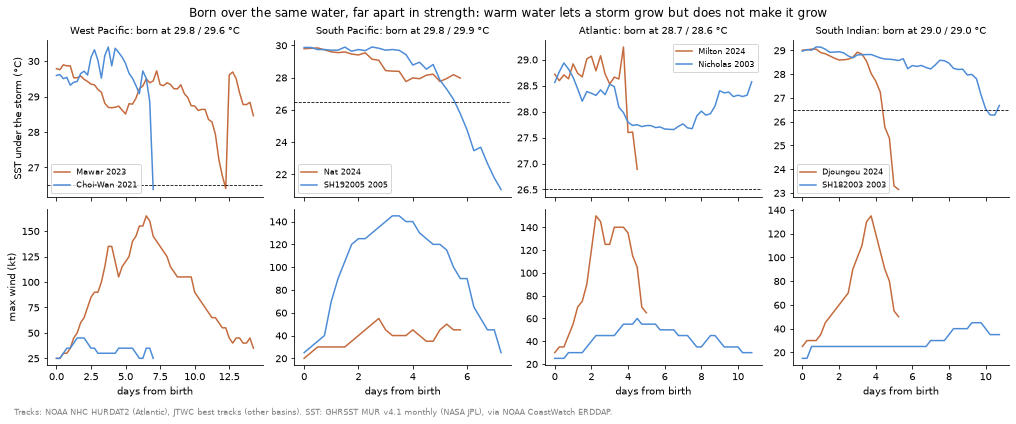

In [15]:
sea_share = g["sst_c"].agg(lambda v: v.notna().mean())
cand = storms[(storms["ts_days"] >= 3) & (sea_share >= 0.9)].dropna(subset=["gen_sst"]).reset_index()
cand["month"] = cand["start"].dt.month
pairs = cand.merge(cand, on=["basin", "month"], suffixes=("_a", "_b"))
pairs = pairs[(pairs["sid_a"] < pairs["sid_b"]) & ((pairs["gen_sst_a"] - pairs["gen_sst_b"]).abs() <= 0.2)]
pairs["gap"] = (pairs["lmi_kt_a"] - pairs["lmi_kt_b"]).abs()
chosen, used = [], set()
for _, p in pairs.sort_values("gap", ascending=False).iterrows():
    if p["basin"] not in used:
        chosen.append(p)
        used.add(p["basin"])

fig, axes = plt.subplots(2, len(chosen), figsize=(14, 5.5), sharex="col", layout="constrained")
for j, p in enumerate(chosen):
    for side, color in (("a", "#c46a3c"), ("b", "#4c8bd6")):
        sid = p[f"sid_{side}"]
        d = rec[rec["sid"] == sid]
        days = (d["t"] - d["t"].iloc[0]).dt.total_seconds() / 86400
        label = f"{storms.loc[sid, 'name'].title() or sid} {storms.loc[sid, 'start']:%Y}"
        axes[0, j].plot(days, d["sst_c"], color=color, label=label)
        axes[1, j].plot(days, d["vmax_kt"], color=color)
    axes[0, j].axhline(WARM_C, color="black", linestyle="--", linewidth=0.8)
    axes[0, j].set_title(f"{p['basin']}: born at {p['gen_sst_a']:.1f} / {p['gen_sst_b']:.1f} °C", fontsize=10)
    axes[0, j].legend(fontsize=8)
    axes[1, j].set_xlabel("days from birth")
axes[0, 0].set_ylabel("SST under the storm (°C)")
axes[1, 0].set_ylabel("max wind (kt)")
fig.suptitle("Born over the same water, far apart in strength: warm water lets a storm grow but does not make it grow")
source_note(fig, CREDIT)

**Reading (ours):**

- **The birth water says almost nothing.** Alone it explains 0–1 % of peak wind and energy, and 0.4 % of the next day's wind change on top of the wind itself. Nearly every storm is born over warm water (section 4), so the birth water barely varies between strong and weak storms.
- **The water now says the most.** Step by step, the SST under the storm adds 8 points of R² to the wind alone (0.12 → 0.19); how that water changes over the next 24 hours adds 2 more (→ 0.21). The message of 5097 lives in the water along the path, moment by moment.
- **Storm totals mostly measure time.** Per storm, the hours over warm water before the peak explain 29 % of peak wind and 40 % of energy, but the hours from birth to peak alone already explain 23 % and 34 %. Most storms stay over warm water until their peak, so "how long it kept growing" and "how long it was fed" are nearly the same number.
- **Warm water is needed, not enough.** The pairs above stay over warm water and still part ways. About 70–80 % of the variation is left to what this data does not hold (wind shear, dry air, land). The music should say "warm water lets storms grow", not "warm water makes every storm strong".

## 6. What high-energy storms look like

Storms ranked by ACE within their own basin: the top 10 % against the bottom half.

In [16]:
storms["ace_rank"] = storms.groupby("basin")["ace"].rank(pct=True)
storms["group"] = np.select([storms["ace_rank"] >= 0.9, storms["ace_rank"] <= 0.5], ["top 10 %", "bottom 50 %"], "middle")
FEATURES = {"lmi_kt": "peak wind (kt)", "min_mslp_hpa": "lowest pressure (hPa)", "ts_days": "days as a named storm",
            "track_km": "distance travelled (km)", "speed_kmh": "mean forward speed (km/h)", "max_dv24_kt": "fastest 24-h strengthening (kt)",
            "warm_hours": "hours over water ≥ 26.5 °C", "gen_sst": "SST at birth (°C)", "abs_gen_lat": "latitude of birth (°)"}
table = storms.groupby("group")[list(FEATURES)].median().T.rename(index=FEATURES)[["bottom 50 %", "middle", "top 10 %"]]
table.loc["rapid intensification (≥ 30 kt in 24 h)"] = storms.groupby("group")["max_dv24_kt"].agg(lambda v: (v >= 30).mean())[table.columns]
table.loc["storms"] = storms["group"].value_counts()[table.columns]
display(Markdown("**Medians** (rapid intensification: share of storms)"))
table.round(2)

**Medians** (rapid intensification: share of storms)

group,bottom 50 %,middle,top 10 %
peak wind (kt),45.00,100.00,137.50
lowest pressure (hPa),991.00,954.00,915.50
days as a named storm,2.25,6.25,10.25
distance travelled (km),1628.20,3231.66,4959.69
mean forward speed (km/h),17.46,17.27,18.56
fastest 24-h strengthening (kt),15.00,35.00,50.00
hours over water ≥ 26.5 °C,42.00,120.00,210.00
SST at birth (°C),29.02,29.10,28.94
latitude of birth (°),15.50,13.25,11.20
rapid intensification (≥ 30 kt in 24 h),0.08,0.69,0.94


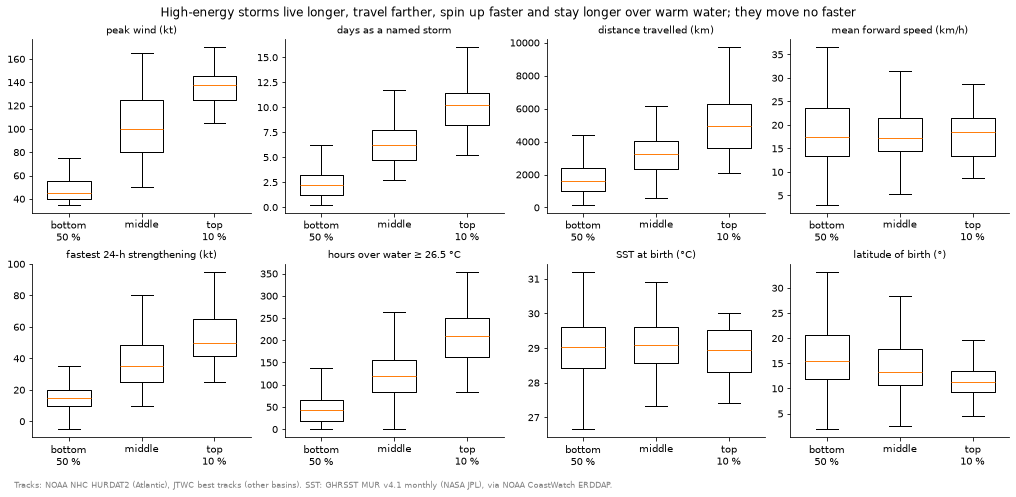

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), layout="constrained")
for ax, col in zip(axes.flat, ["lmi_kt", "ts_days", "track_km", "speed_kmh", "max_dv24_kt", "warm_hours", "gen_sst", "abs_gen_lat"]):
    data = [storms.loc[storms["group"] == k, col].dropna() for k in ("bottom 50 %", "middle", "top 10 %")]
    ax.boxplot(data, showfliers=False, widths=0.6)
    ax.set_xticks([1, 2, 3], ["bottom\n50 %", "middle", "top\n10 %"])
    ax.set_title(FEATURES[col], fontsize=10)
fig.suptitle("High-energy storms live longer, travel farther, spin up faster and stay longer over warm water; they move no faster")
source_note(fig, CREDIT)

## 7. The life of a storm: wind, water, direction and speed together

5097 shows each storm as a track over the water. Here every storm that leaves warm water over the sea is lined up at the moment it does: the first record under 26.5 °C after its last record at or above it. Around that moment: its wind, the water under it, its latitude, its forward speed and which way it moves. Medians over the storms, with the middle half shaded.

- Storms that leave warm water over the sea: **218** of 517 (42%); the rest end over land or over warm water.
- Their peak comes a median **36 hours** before they leave warm water (middle half 18–72 h).

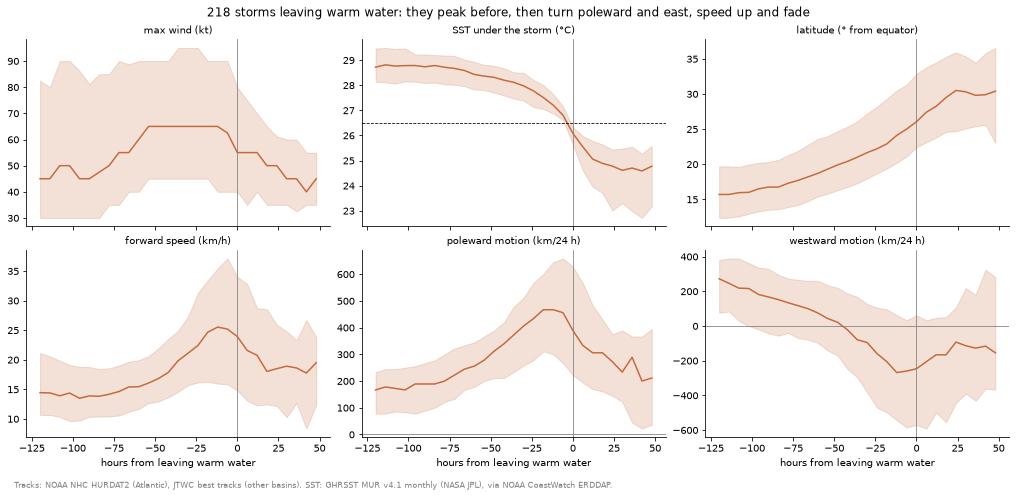

In [18]:
def exit_time(d):
    """Time of the first record below 26.5 °C after the storm's last record over warm water, if over the sea."""
    warm = d["warm"].values
    if not warm.any():
        return pd.NaT
    k = np.flatnonzero(warm)[-1] + 1
    if k >= len(d) or np.isnan(d["sst_c"].values[k]):
        return pd.NaT
    return d["t"].values[k]


exits = pd.to_datetime(rec.groupby("sid").apply(exit_time, include_groups=False)).dropna()
comp = rec[rec["sid"].isin(exits.index)].copy()
comp["hours"] = (comp["t"] - comp["sid"].map(exits)).dt.total_seconds() / 3600
comp = comp[comp["hours"].between(-120, 48)]
comp["abs_lat"] = comp["lat"].abs()
PANELS = {"vmax_kt": "max wind (kt)", "sst_c": "SST under the storm (°C)", "abs_lat": "latitude (° from equator)",
          "speed_kmh": "forward speed (km/h)", "pole_km": "poleward motion (km/24 h)", "west_km": "westward motion (km/24 h)"}
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True, layout="constrained")
for ax, col in zip(axes.flat, PANELS):
    q = comp.groupby("hours")[col].quantile([0.25, 0.5, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], color="#c46a3c", alpha=0.2)
    ax.plot(q.index, q[0.5], color="#c46a3c")
    ax.axvline(0, color="gray", linewidth=0.8)
    if col == "sst_c":
        ax.axhline(WARM_C, color="black", linestyle="--", linewidth=0.8)
    if col in ("pole_km", "west_km"):
        ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(PANELS[col], fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("hours from leaving warm water")
fig.suptitle(f"{len(exits)} storms leaving warm water: they peak before, then turn poleward and east, speed up and fade")
source_note(fig, CREDIT)

peak_t = rec.loc[rec.groupby("sid")["vmax_kt"].idxmax()].set_index("sid")["t"]
lead = ((exits - peak_t.reindex(exits.index)).dt.total_seconds() / 3600)
display(Markdown(f"- Storms that leave warm water over the sea: **{len(exits)}** of {len(storms)} ({len(exits) / len(storms):.0%}); the rest end over land or over warm water.\n"
                 f"- Their peak comes a median **{lead.median():.0f} hours** before they leave warm water (middle half {lead.quantile(0.25):.0f}–{lead.quantile(0.75):.0f} h)."))

### 7.1 Direction and speed against the water

Every record over water, by which way the storm moves over the next 24 hours and how fast, against the SST under it and its next 24-hour wind change.

**By heading** (median SST, median SST change over the 24 hours, mean wind change)

,records,sst_c,sst_change_c,dv24_kt
heading,,,,
west,4830,28.69,-0.09,6.88
poleward,3743,28.42,-0.43,1.77
east,1448,28.11,-0.33,-0.28
equatorward,340,28.05,0.16,0.74


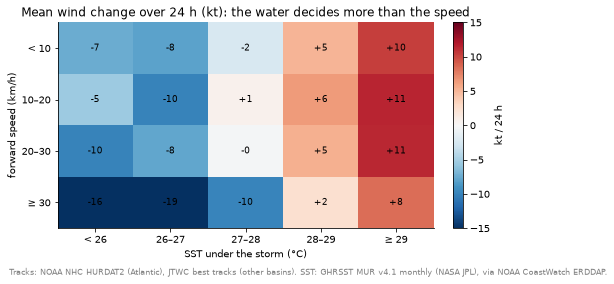

In [19]:
d = over_water.dropna(subset=["speed_kmh", "pole_km", "west_km"]).copy()
heading = np.degrees(np.arctan2(d["pole_km"], d["west_km"]))  # 0 = west, 90 = poleward, 180 = east
d["heading"] = pd.cut(heading, [-180, -135, -45, 45, 135, 180], labels=["east", "equatorward", "west", "poleward", "east "])
d["heading"] = d["heading"].astype(str).str.strip()
d["speed"] = pd.cut(d["speed_kmh"], [0, 10, 20, 30, 500], labels=["< 10", "10–20", "20–30", "≥ 30"])
by_heading = d.groupby("heading").agg(records=("dv24_kt", "size"), sst_c=("sst_c", "median"),
                                       sst_change_c=("sst_next24_c", lambda s: (s - d.loc[s.index, "sst_c"]).median()),
                                       dv24_kt=("dv24_kt", "mean")).loc[["west", "poleward", "east", "equatorward"]]
display(Markdown("**By heading** (median SST, median SST change over the 24 hours, mean wind change)"))
display(by_heading.round(2))

heat = d.assign(sst=pd.cut(d["sst_c"], [0, 26, 27, 28, 29, 40], labels=["< 26", "26–27", "27–28", "28–29", "≥ 29"]))
heat = heat.pivot_table(index="speed", columns="sst", values="dv24_kt", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=-15, vmax=15, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
for (i, j), v in np.ndenumerate(heat.values):
    ax.annotate(f"{v:+.0f}", (j, i), ha="center", va="center", fontsize=9)
ax.set(xlabel="SST under the storm (°C)", ylabel="forward speed (km/h)", title="Mean wind change over 24 h (kt): the water decides more than the speed")
fig.colorbar(im, ax=ax, label="kt / 24 h")
source_note(fig, CREDIT)

## 8. Hot seasons

Ours, beyond what 5097 claims. For each basin and season: the mean SST of its main development region in its peak months, against the season's storm count and energy. Southern Hemisphere seasons run from July to June and are named by the year they end in.

| Basin | Region | Peak months |
| --- | --- | --- |
| Atlantic | 10–20° N, 85–20° W | August–October |
| West Pacific | 5–20° N, 120–170° E | July–October |
| South Indian | 5–20° S, 40–135° E | January–March |
| South Pacific | 5–20° S, 135° E–150° W | January–March |

,seasons,ρ SST–storms,ρ SST–ACE,ρ SST–major storms,2023 SST rank,2023 ACE rank
basin,,,,,,
Atlantic,22,0.67,0.57,0.60,1,8
West Pacific,22,0.02,-0.58,-0.42,10,11
South Indian,21,0.16,-0.12,0.12,18,2
South Pacific,21,0.28,0.15,-0.17,16,13


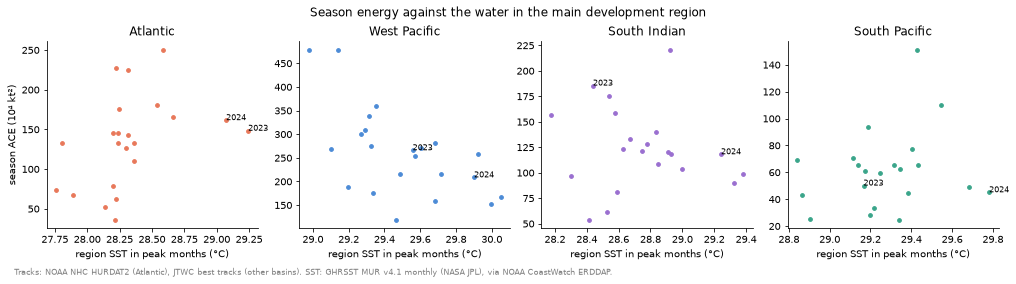

In [20]:
REGION = {"Atlantic": ((10, 20), (275, 340), (8, 9, 10)), "West Pacific": ((5, 20), (120, 170), (7, 8, 9, 10)),
          "South Indian": ((-20, -5), (40, 135), (1, 2, 3)), "South Pacific": ((-20, -5), (135, 210), (1, 2, 3))}


def region_mean(sst, lat_range, lon_range):
    rows = (GRID_LAT >= lat_range[0]) & (GRID_LAT <= lat_range[1])
    cols = ((GRID_LON % 360) >= lon_range[0]) & ((GRID_LON % 360) <= lon_range[1])
    x = sst[rows][:, cols]
    w = np.broadcast_to(np.cos(np.radians(GRID_LAT[rows]))[:, None], x.shape)
    ok = np.isfinite(x)
    return float((x[ok] * w[ok]).sum() / w[ok].sum())


monthly = []
for m in MONTHS:
    sst = read_mur(m)
    for b, (la, lo, months) in REGION.items():
        if m.month in months:
            monthly.append((b, m.year, region_mean(sst, la, lo)))
season = pd.DataFrame(monthly, columns=["basin", "season", "region_sst_c"]).groupby(["basin", "season"]).mean().reset_index()
every = rec_all.assign(ace=np.where(rec_all["vmax_kt"] >= 35, rec_all["vmax_kt"] ** 2 / 1e4, 0.0)).groupby("sid").agg(
    basin=("basin", "first"), start=("t", "min"), ace=("ace", "sum"), lmi_kt=("vmax_kt", "max"))
every["season"] = np.where(every["basin"].str.startswith("South") & (every["start"].dt.month >= 7),
                           every["start"].dt.year + 1, every["start"].dt.year)
activity = every.groupby(["basin", "season"]).agg(storms=("ace", "size"), ace=("ace", "sum"),
                                                    majors=("lmi_kt", lambda v: (v >= 96).sum())).reset_index()
season = season.merge(activity, on=["basin", "season"], how="left").fillna({"storms": 0, "ace": 0, "majors": 0})
season = season[~(season["basin"].str.startswith("South") & (season["season"] == YEARS[0]))]  # its first half is before 2003

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), layout="constrained")
rows = []
for ax, b in zip(axes, BASINS):
    x = season[season["basin"] == b]
    ax.scatter(x["region_sst_c"], x["ace"], color=BASIN_COLOR[b], s=14)
    for _, r in x[x["season"].isin([2023, 2024])].iterrows():
        ax.annotate(str(int(r["season"])), (r["region_sst_c"], r["ace"]), fontsize=8)
    ax.set(title=b, xlabel="region SST in peak months (°C)")
    rows.append({"basin": b, "seasons": len(x),
                 "ρ SST–storms": spearmanr(x["region_sst_c"], x["storms"]).statistic,
                 "ρ SST–ACE": spearmanr(x["region_sst_c"], x["ace"]).statistic,
                 "ρ SST–major storms": spearmanr(x["region_sst_c"], x["majors"]).statistic,
                 "2023 SST rank": int(x["region_sst_c"].rank(ascending=False)[x["season"] == 2023].iloc[0]),
                 "2023 ACE rank": int(x["ace"].rank(ascending=False)[x["season"] == 2023].iloc[0])})
axes[0].set_ylabel("season ACE (10⁴ kt²)")
fig.suptitle("Season energy against the water in the main development region")
source_note(fig, CREDIT)
pd.DataFrame(rows).set_index("basin").round(2)

**Reading (ours):** a hotter main development region goes with a stormier season only in the Atlantic. In the West Pacific the hot seasons are the calmer ones, likely because El Niño moves the West Pacific storms east of the region, away from where the water is measured; the southern basins show little either way. 2023 had the hottest Atlantic main development region of these 22 seasons but ranks only 8th in energy.

### 8.1 The warm pool breathes with the season

The area of each basin's water at or above 26.5 °C, month by month, against the number of storms active on an average day of that month. The eight storm years folded into one, as one season.

,ρ warm area – active storms (months),"warm area, min–max month (million km²)"
basin,,
Atlantic,0.79,11–25
West Pacific,0.75,15–28
South Indian,0.75,10–24
South Pacific,0.68,16–28


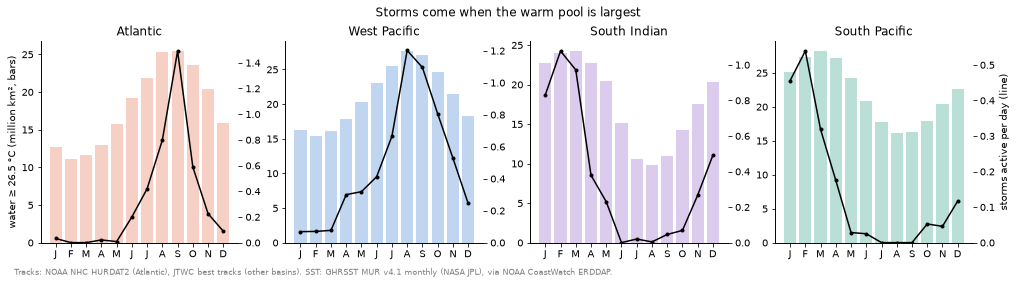

In [21]:
BASIN_BOX = {"Atlantic": ((0, 45), (260, 360)), "West Pacific": ((0, 45), (100, 180)),
             "South Indian": ((-45, 0), (30, 135)), "South Pacific": ((-45, 0), (135, 240))}
cell_km2 = (111.2 * STEP) ** 2 * np.cos(np.radians(GRID_LAT))[:, None]


def warm_area(sst, lat_range, lon_range):
    rows = (GRID_LAT >= lat_range[0]) & (GRID_LAT <= lat_range[1])
    cols = ((GRID_LON % 360) >= lon_range[0]) & ((GRID_LON % 360) < lon_range[1])
    return float(np.where(sst[rows][:, cols] >= WARM_C, cell_km2[rows], 0).sum() / 1e6)


warm = []
for m in MONTHS[MONTHS.year.isin(STORM_YEARS)]:
    sst = read_mur(m)
    warm += [(b, m, warm_area(sst, *BASIN_BOX[b])) for b in BASINS]
warm = pd.DataFrame(warm, columns=["basin", "month", "warm_mkm2"])
days = rec.assign(day=rec["t"].dt.floor("D")).groupby(["basin", "day"])["sid"].nunique().rename("active").reset_index()
days["month"] = days["day"].dt.to_period("M")
ndays = pd.Series({m: m.days_in_month for m in MONTHS})  # active storms per day of the month
active = days.groupby(["basin", "month"])["active"].sum().reset_index()
active["active"] /= active["month"].map(ndays)
warm = warm.merge(active, on=["basin", "month"], how="left").fillna({"active": 0})
warm["moy"] = warm["month"].dt.month

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), layout="constrained")
rows = []
for ax, b in zip(axes, BASINS):
    clim = warm[warm["basin"] == b].groupby("moy")[["warm_mkm2", "active"]].mean()
    ax.bar(clim.index, clim["warm_mkm2"], color=BASIN_COLOR[b], alpha=0.35)
    ax2 = ax.twinx()
    ax2.plot(clim.index, clim["active"], color="black", marker=".")
    ax.set(title=b, xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"))
    ax2.set_ylim(0, None)
    w = warm[warm["basin"] == b]
    rows.append({"basin": b, "ρ warm area – active storms (months)": spearmanr(w["warm_mkm2"], w["active"]).statistic,
                 "warm area, min–max month (million km²)": f"{clim['warm_mkm2'].min():.0f}–{clim['warm_mkm2'].max():.0f}"})
axes[0].set_ylabel("water ≥ 26.5 °C (million km², bars)")
ax2.set_ylabel("storms active per day (line)")
fig.suptitle("Storms come when the warm pool is largest")
source_note(fig, CREDIT)
pd.DataFrame(rows).set_index("basin").round(2)

## 9. Track candidates: one storm per track

The album plays one storm per track (ours, decided 2026-11-14): its wind as tempo and percussion, as in the earlier single-storm album; the water under it as a slow low line that takes the place of that album's melody; landfall as the big drum. The movement of storms as a flock goes to a separate album.

A good track is a storm whose wind follows the water: it strengthens over water warmer than its basin's neutral SST (section 5.1) and weakens over cooler water, and its water crosses that line, so that the ocean line has somewhere to go.

**Pool**: every named storm of 2003–2024 whose every month has a map: all of the eight storm years, and the storms of the other years that stay within July–October (northern basins) or January–March (southern basins). This includes the five storms of the earlier single-storm album: Dennis and Emily (2005), Felix (2007), Gustav (2008) and Florence (2018).

**Score**, per storm, over the sea and away from landfall (as in 5.1). Each 6-hour step is

- *warm* when the SST is at least 0.5 °C above the basin's neutral SST, *cool* when at least 0.5 °C below it;
- *strengthening* when the wind rises 5 kt or more over the next 24 hours, *weakening* when it falls 5 kt or more;
- *in step* when warm and strengthening, or cool and weakening; *out of step* when warm and weakening, or cool and strengthening.

The share of steps in step is the plain score. Since many storms are fully in step over a dozen steps, they are ranked by the lower end of its 95 % Wilson interval: a storm in step over 40 steps ranks above one in step over 15. Candidates must live at least 5 days as a named storm and reach 96 kt (category 3: a wide tempo range). Each is tagged by how it weakens: over cool water, on land, or both. The storms of the earlier album weaken on land only, so they are listed whether or not they qualify.

In [22]:
NEUTRAL = checks["all records"].to_dict()
EARLIER = {"AL042005": "Dennis", "AL052005": "Emily", "AL062007": "Felix", "AL072008": "Gustav", "AL062018": "Florence"}
in_maps = rec_all.groupby("sid")["t"].agg(lambda t: t.dt.to_period("M").isin(MONTHS).all())
pool = add_water(rec_all[rec_all["sid"].map(in_maps)].reset_index(drop=True))
pool["neutral_c"] = pool["basin"].map(NEUTRAL)
landed = pool["sst_c"].isna() | pool["sst_next24_c"].isna()
side = np.select([pool["sst_c"] >= pool["neutral_c"] + 0.5, pool["sst_c"] <= pool["neutral_c"] - 0.5], ["warm", "cool"], "")
trend = np.select([pool["dv24_kt"] >= 5, pool["dv24_kt"] <= -5], ["up", "down"], "")
judged = (side != "") & (trend != "") & ~landed
pool["in_step"] = pd.Series(((side == "warm") & (trend == "up")) | ((side == "cool") & (trend == "down")), index=pool.index).astype(float).where(judged)
pool["cool"] = pool["sst_c"] <= pool["neutral_c"] - 0.5

pg = pool.groupby("sid")
cands = pd.DataFrame({
    "basin": pg["basin"].first(), "name": pg["name"].first().str.title(), "start": pg["t"].min().dt.date,
    "named days": pg["vmax_kt"].agg(lambda v: (v >= 34).sum() * 0.25),
    "peak kt": pg["vmax_kt"].max(),
    "SST min–max (°C)": pg["sst_c"].agg(lambda v: f"{v.min():.1f}–{v.max():.1f}"),
    "days over cool water": pg["cool"].sum() * 0.25,
    "landfalls": pg["sst_c"].agg(lambda v: int((v.isna() & v.shift().notna()).sum())),
    "judged steps": pg["in_step"].count(),
    "in step": pg["in_step"].mean(),
})
n = cands["judged steps"].replace(0, np.nan).astype(float)
z = 1.96
p_hat = cands["in step"]
cands["score"] = (p_hat + z**2 / (2 * n) - z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))) / (1 + z**2 / n)
cands["weakens"] = np.select([(cands["days over cool water"] >= 1) & (cands["landfalls"] > 0), cands["days over cool water"] >= 1,
                              cands["landfalls"] > 0], ["cool water and land", "cool water", "land"], "neither")
cands["earlier album"] = cands.index.map(EARLIER).notna()
ok = (cands["named days"] >= 5) & (cands["peak kt"] >= 96) & (cands["weakens"] != "neither")
ranked = cands[ok].sort_values("score", ascending=False)
COLS = ["basin", "name", "start", "named days", "peak kt", "SST min–max (°C)", "weakens", "judged steps", "in step", "score"]
display(Markdown(f"**{ok.sum()} of {len(cands)} storms qualify.** The top 5 of each way of weakening:"))
display(ranked.groupby("weakens", group_keys=False).head(5).sort_values(["weakens", "score"], ascending=[True, False])[COLS].round(2))
display(Markdown("**The earlier album's storms:**"))
cands.loc[list(EARLIER), COLS].assign(rank=[int((ranked["score"] > cands.loc[s_, "score"]).sum()) + 1 for s_ in EARLIER]).round(2)

**283 of 1159 storms qualify.** The top 5 of each way of weakening:

,basin,name,start,named days,peak kt,SST min–max (°C),weakens,judged steps,in step,score
sid,,,,,,,,,,
SH102007,South Indian,Dora,2007-01-28,11.25,115,25.8–29.6,cool water,40,1.0,0.91
SH042005,South Indian,,2004-11-20,8.00,140,24.1–28.2,cool water,24,1.0,0.86
SH082014,South Indian,Colin,2014-01-07,5.50,120,20.1–29.2,cool water,24,1.0,0.86
SH162003,South Indian,,2003-02-07,6.50,105,24.8–28.9,cool water,23,1.0,0.86
SH122003,South Pacific,,2003-01-24,6.25,125,25.0–29.3,cool water,23,1.0,0.86
WP192014,West Pacific,Vongfong,2014-10-02,10.25,155,25.6–30.0,cool water and land,27,1.0,0.88
WP142022,West Pacific,Muifa,2022-09-05,9.00,110,22.6–30.1,cool water and land,25,1.0,0.87
WP132004,West Pacific,,2004-07-25,6.75,115,26.0–29.3,cool water and land,18,1.0,0.82
WP022003,West Pacific,,2003-04-08,16.00,135,17.4–29.7,cool water and land,17,1.0,0.82


**The earlier album's storms:**

,basin,name,start,named days,peak kt,SST min–max (°C),weakens,judged steps,in step,score,rank
sid,,,,,,,,,,,
AL042005,Atlantic,Dennis,2005-07-04,5.75,130,28.5–29.6,land,19,0.84,0.62,121
AL052005,Atlantic,Emily,2005-07-11,9.25,140,28.1–29.5,land,31,0.77,0.60,134
AL062007,Atlantic,Felix,2007-08-31,4.25,150,28.3–29.3,land,11,0.82,0.52,184
AL072008,Atlantic,Gustav,2008-08-25,8.00,125,27.6–30.1,land,21,0.57,0.37,246
AL062018,Atlantic,Florence,2018-08-31,15.50,130,25.5–29.0,cool water and land,32,0.44,0.28,270


### 9.1 What the tracks would play

Each storm's wind (the tempo) over the water under it (the ocean line), from birth to death. The dashed line is the basin's neutral SST; grey bands are steps over land.

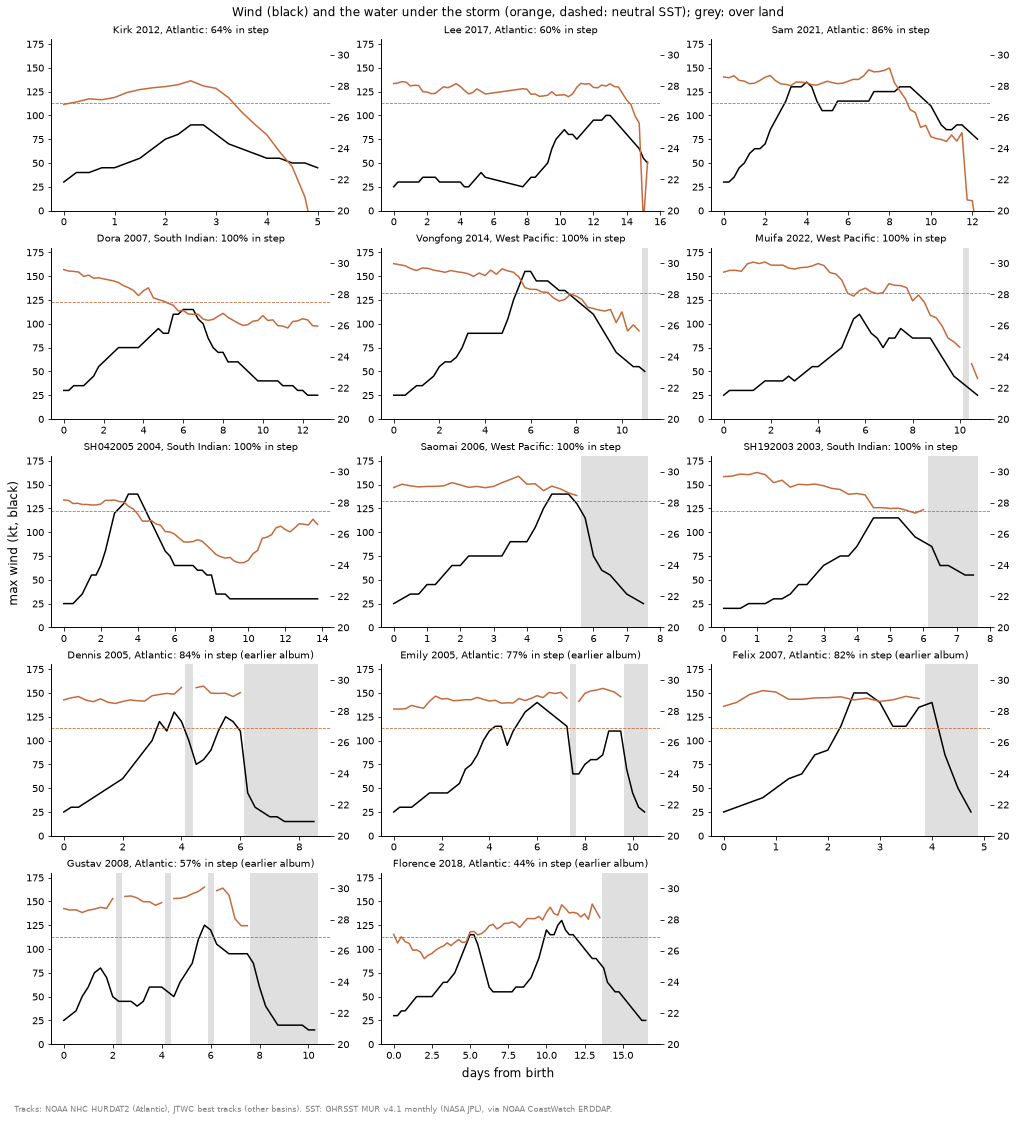

In [23]:
top = list(ranked.groupby("weakens", group_keys=False).head(2).index)
PICKS = ["AL112012", "AL142017", "AL182021"]  # the album's tracks (sections 9.2 and 11.3)
show = list(dict.fromkeys(PICKS + top + list(EARLIER)))
fig, axes = plt.subplots(int(np.ceil(len(show) / 3)), 3, figsize=(14, 3 * np.ceil(len(show) / 3)), layout="constrained")
for ax, sid in zip(axes.flat, show):
    d = pool[pool["sid"] == sid]
    days = (d["t"] - d["t"].iloc[0]).dt.total_seconds() / 86400
    for x in days[d["sst_c"].isna()]:
        ax.axvspan(x - 0.125, x + 0.125, color="gray", alpha=0.25, linewidth=0)
    ax.plot(days, d["vmax_kt"], color="black", linewidth=1.5)
    ax2 = ax.twinx()
    ax2.plot(days, d["sst_c"], color="#c46a3c")
    ax2.axhline(NEUTRAL[d["basin"].iloc[0]], color="#c46a3c", linestyle="--", linewidth=0.8)
    ax2.set_ylim(20, 31)
    c = cands.loc[sid]
    tag = " (earlier album)" if c["earlier album"] else ""
    ax.set_title(f"{c['name'] or sid} {c['start']:%Y}, {c['basin']}: {c['in step']:.0%} in step{tag}", fontsize=10)
    ax.set_ylim(0, 180)
for ax in axes.flat[len(show):]:
    ax.set_visible(False)
fig.supxlabel("days from birth")
fig.supylabel("max wind (kt, black)")
fig.suptitle("Wind (black) and the water under the storm (orange, dashed: neutral SST); grey: over land")
source_note(fig, CREDIT)

### 9.2 The sharpest turns from warm water to cool, away from land

The album keeps only storms that go from warm water to cool and never come near land (user, 2026-11-14), and of those the ones whose water changes the most abruptly.

**Pool**: the Atlantic hurricanes of section 9's pool (64 kt or more) that

- never come within 200 km of land, over their whole HURDAT2 life, extratropical records included: land is the grid cells the SST map leaves empty, plus the small islands the 0.25° grid misses (Bermuda, the Azores, the Lesser Antilles, the Cape Verde Islands, Madeira, Sable Island) and the coasts north of the map's 55° N edge (Labrador, Greenland, Iceland, the Faroes, Scotland, Norway);
- peak over warm water: SST at the peak at least 0.5 °C above the neutral SST;
- reach cool water while still tropical: SST at least 1.5 °C below the neutral SST after the peak.

**Ranked** by the largest fall of the SST under the storm in 24 hours after its peak, while it is tropical. Also shown: the hours from the last record at least 1 °C above the neutral SST to the first at least 1 °C below it.

In [24]:
from scipy.spatial import cKDTree

ISLANDS = {"Bermuda": (32.3, -64.8), "Flores": (39.4, -31.2), "Terceira": (38.7, -27.2), "São Miguel": (37.8, -25.5),
           "Barbuda": (17.6, -61.8), "Antigua": (17.1, -61.8), "Anguilla": (18.2, -63.05), "St Croix": (17.7, -64.8),
           "Guadeloupe": (16.2, -61.6), "Martinique": (14.6, -61.0), "Barbados": (13.2, -59.5), "Santo Antão": (17.0, -25.2),
           "Sal": (16.7, -22.9), "Brava": (14.85, -24.7), "Madeira": (32.7, -17.0), "Sable Island": (43.9, -59.9)}
NORTH_COASTS = {"Labrador": (57.5, -61.5), "Cape Farewell": (59.8, -43.9), "Iceland": (63.4, -19.0), "Faroes": (62.0, -6.8),
                "Outer Hebrides": (58.0, -6.8), "Shetland": (60.3, -1.3), "Norway": (61.0, 5.0)}  # beyond the SST map's 55° N edge
LAND_KM = 200
DAY = pd.Timedelta("24h")


def unit(lat, lon):
    lat, lon = np.radians(lat), np.radians(lon)
    return np.column_stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])


land_cells = np.isnan(read_mur(pd.Period("2021-09", "M")))  # empty cells: land (September, no sea ice)
li, lj = np.nonzero(land_cells)
atlantic = (GRID_LON[lj] > -110) & (GRID_LON[lj] < 20)
points = list(ISLANDS.values()) + list(NORTH_COASTS.values())
land_tree = cKDTree(unit(np.r_[GRID_LAT[li][atlantic], [p[0] for p in points]], np.r_[GRID_LON[lj][atlantic], [p[1] for p in points]]))
life_land_km = hurdat.groupby("sid").apply(lambda d: land_tree.query(unit(d["lat"], d["lon"]))[0].min() * 6371, include_groups=False)


def turn(d):
    """How a storm's water turns from warm to cool after its peak."""
    d = d.reset_index(drop=True)
    neutral = NEUTRAL[d["basin"].iloc[0]]
    peak = d["vmax_kt"].idxmax()
    after = d.loc[peak:].set_index("t")["sst_c"]
    fall = after - after.reindex(after.index + DAY).to_numpy()
    warm, cool = after.index[after >= neutral + 1], after.index[after <= neutral - 1]
    cross = [(cool[cool > w].min() - w) / pd.Timedelta("1h") for w in warm if (cool > w).any()]
    return pd.Series({"name": d["name"].iloc[0].title(), "year": d["t"].iloc[0].year, "peak kt": d["vmax_kt"].max(),
                      "SST at peak (°C)": d.loc[peak, "sst_c"], "coolest after peak (°C)": after.min(),
                      "largest 24-h fall (°C)": fall.max(), "warm to cool (h)": min(cross, default=np.nan), "neutral": neutral})


hurricanes = pool[pool["basin"] == "Atlantic"].groupby("sid").filter(lambda d: d["vmax_kt"].max() >= 64)
turns = hurricanes.groupby("sid").apply(turn, include_groups=False)
turns["nearest land (km)"] = life_land_km.reindex(turns.index)
sea = turns["nearest land (km)"] >= LAND_KM
turning = (turns["SST at peak (°C)"] >= turns["neutral"] + 0.5) & (turns["coolest after peak (°C)"] <= turns["neutral"] - 1.5)
sharpest = turns[sea & turning].sort_values("largest 24-h fall (°C)", ascending=False).drop(columns="neutral")
display(Markdown(f"**{len(turns)} Atlantic hurricanes; {sea.sum()} never come within {LAND_KM} km of land; "
                 f"{(sea & turning).sum()} of those turn from warm water to cool.** Those that turn but come near land:"))
display(turns[~sea & turning].sort_values("largest 24-h fall (°C)", ascending=False)[["name", "year", "largest 24-h fall (°C)", "nearest land (km)"]].round(1))
sharpest.round(1)

**162 Atlantic hurricanes; 24 never come within 200 km of land; 6 of those turn from warm water to cool.** Those that turn but come near land:

,name,year,largest 24-h fall (°C),nearest land (km)
sid,,,,
AL082014,Gonzalo,2014,15.8,0.0
AL122021,Larry,2021,13.9,23.7
AL072010,Earl,2010,12.4,3.1
AL102003,Fabian,2003,10.6,72.9
AL052024,Ernesto,2024,10.4,0.0
AL112010,Igor,2010,10.3,17.0
AL072004,Gaston,2004,9.1,10.0
AL122012,Leslie,2012,7.1,8.7
AL052019,Dorian,2019,6.5,9.0


,name,year,peak kt,SST at peak (°C),coolest after peak (°C),largest 24-h fall (°C),warm to cool (h),nearest land (km)
sid,,,,,,,,
AL142017,Lee,2017,100,28.0,19.2,7.9,30.0,447.4
AL112012,Kirk,2012,90,28.3,17.1,7.7,24.0,841.8
AL182021,Sam,2021,135,28.2,18.3,6.1,30.0,354.3
AL152023,Nigel,2023,85,28.4,20.5,6.0,36.0,212.3
AL062010,Danielle,2010,115,28.5,24.5,2.5,30.0,460.6
AL082017,Gert,2017,95,27.8,23.9,NaN,NaN,411.6


**Reading (ours):** only six Atlantic hurricanes of the pool go from warm water to cool without coming within 200 km of land. Lee 2017, Kirk 2012 and Sam 2021 turn the fastest: the water under them falls 6–8 °C in a day after the peak, and crosses from 1 °C above the neutral SST to 1 °C below it in 24–30 hours. Nigel 2023 follows closely (6.0 °C, 36 hours); Danielle 2010 crosses as fast but its water falls only 2.5 °C in a day. These three are the album's tracks (section 11.3).

The storms whose water falls faster still (Gonzalo 2014, Larry 2021, Earl 2010, Igor 2010) all reach Bermuda, Newfoundland or Nova Scotia: the fastest falls happen where a storm races north across the Gulf Stream's edge, close to those coasts. The fall is steep also because the SST is a monthly mean, which changes at the month's edge.

## 10. Message summary

| # | EIC page | Message | Key number (this notebook) | Track data |
| --- | --- | --- | --- | --- |
| 1 | [5097](https://svs.gsfc.nasa.gov/5097/) | Storms form over water warmer than ~26.5 °C | 87 % (Atlantic) to 100 % (West Pacific, South Pacific) of named storms are born over water at or above 26.5 °C; median 28.3–29.4 °C | SST under each storm record |
| 2 | [5097](https://svs.gsfc.nasa.gov/5097/) | Warmer water, more intense storms | Storms strengthen over water warmer than 27–28 °C and weaken below it; the share strengthening in 24 h rises from about 20 % under 26.5 °C to 77 % at 30 °C. The link is immediate. | 24-hour wind change against SST |
| 2b | ours | The water along the path, not the birth water | Birth SST explains 0–1 % of peak wind and energy; step by step, the SST now adds 8 points of R² to the next day's wind change, its change ahead 2 more, the birth SST 0.4 | SST under each record and its 24-hour change |
| 2a | ours | Time over warm water is the fuel | Hours over water ≥ 26.5 °C: ρ 0.83 with energy (ACE), 0.74 with peak wind; the mean SST alone: ρ ≈ 0 | Warm hours per storm |
| 3 | ours | High-energy storms | Top 10 %: 10 days as a named storm, 5,000 km, 94 % rapidly intensify, born at 11°; bottom half: 2 days, 1,600 km, 8 %, 15°. Same forward speed (17–19 km/h) | Storm table |
| 4 | ours | A storm's life | Peak about 36 h before leaving warm water; in those hours it turns poleward and east and its forward speed nearly doubles | Composite around leaving warm water |
| 4a | ours | Hot seasons | Only the Atlantic gets stormier in hot seasons (ρ 0.67 storms, 0.57 ACE over 22 seasons); the West Pacific goes the other way (ACE ρ −0.58), the southern basins show little. 2023 had the warmest Atlantic main development region of 2003–2024, 8th in ACE | Season SST and activity |
| 5 | [40487](https://svs.gsfc.nasa.gov/gallery/nasaand-hurricanes/), ours | Warm pool and storm season | Warm area and active storms rise and fall together (ρ 0.58–0.75 by month) | Monthly warm area per basin |

## 11. From the data to music (ours)

The album plays one storm per track and joins two things: the storm's wind, as the earlier single-storm album played it, and the water under it, which that album did not have. The movement of storms as a flock goes to a separate album.

### 11.1 What the data says the music must do

| Finding | Section | Consequence for the music |
| --- | --- | --- |
| The birth water says nothing about a storm's energy | 5.3, 5.4 | Nothing is set once at birth. The water is followed step by step along the path |
| The water under the storm goes with whether it strengthens or weakens, not with how strong it is now | 5.1 | The water drives the direction of change, not the loudness. The wind itself stays on tempo and percussion |
| The two move at the same moment | 5.2 | The ocean line and the tempo change together, with no delay |
| A line at about 27–28 °C | 5.1 | One threshold: above it the ocean line is full and in the key, below it the line sags and thins |
| Warm water lets storms grow, it does not make them grow | 5.4, 5.5 | Some steps are warm but weakening. They are heard as they are: a full ocean line under a slowing tempo |
| Storms weaken over cool water or on land | 7, 9 | Two endings, told apart: the ocean line cools and sags, or it breaks off at landfall under the big drum. This album plays only the first (section 11.3) |

### 11.2 The design

| Layer | Data | Sound | Screen |
| --- | --- | --- | --- |
| Wind (result) | Maximum wind | Tempo and percussion layers by category, as in the earlier album | Storm size and spin |
| Water (cause) | SST under the storm against the basin's neutral SST | A slow, low line (cello or low brass), one note held over one or two bars, in the place of the earlier album's melody. Above the neutral SST: held on chord tones, full and heavy. Below it: bending flat, leaving the chord, thinning | The SST field under the globe with the 26.5 °C line, as 5097 draws it |
| Landfall (event) | The storm's centre over land | The ocean line breaks off; the big drum strikes, as in the earlier album | The storm reaches the coast |

The melody of the earlier album is removed: it drew the 24-hour wind change, which the tempo already plays. The water takes its place, so the number of layers stays the same.

The ocean is heard as weight and pressure, never as brightness: warm water is the fuel of a disaster, and bad news must not sound cheerful (album guide).

### 11.3 Tracks (decided 2026-11-14)

Three Atlantic storms that grow over warm water and weaken over cool water, never near land, with the sharpest turn from one to the other (section 9.2). The user dropped the storms that stay over warm water or weaken on land (Emily 2005, Felix 2007; user, 2026-11-14): the album tells one story, the water going cold under the storm.

| Track | Life (section 12) | Peak | SST at peak | Coolest while tropical | Largest 24-h fall | Warm to cool | Nearest land |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Kirk 2012 | 5.25 days | 90 kt | 28.3 °C | 17.1 °C | 7.7 °C | 24 h | Azores, 840 km |
| Lee 2017 | 15.5 days | 100 kt | 28.0 °C | 19.2 °C | 7.9 °C | 30 h | Cape Verde Islands, 450 km |
| Sam 2021 | 12.5 days | 135 kt | 28.2 °C | 18.3 °C | 6.1 °C | 30 h | Bermuda, 350 km |

"Warm to cool": from the last record 1 °C above the Atlantic's neutral SST (26.9 °C) to the first 1 °C below it.

- **Kirk** is short: two and a half days up over 26.8–28.3 °C water, then north into cold water, losing half its wind (90 → 45 kt) in two days.
- **Lee** drifts weak for nine days, falls apart into a remnant low and comes back; it grows to category 3 over 27.4–28.2 °C water east of Bermuda, then races north-east and fades.
- **Sam** grows over 28–29 °C water to category 4 and weakens as it moves north over cooler water.

None makes landfall, so the album has no big drum.


## 12. Export the tracks

The three storms of section 11.3, exported for the app into `data/hot_oceans/tracks/` (see [data-guide.md](../docs/data-guide.md#music-data-tracks)).

**What a track plays**: the storm's whole life, as the earlier single-storm album played it. It starts at the first record that is a tropical depression or stronger (`TD TS HU`) and ends at the first record after the peak that falls below tropical storm strength (34 kt) or stops being tropical (extratropical, a remnant low). Every HURDAT2 record in between is kept, the synoptic ones and the special ones (`L` landfall, `I` peak), so the big drum strikes at the landfall's own time.

**One CSV per storm**, a row per record:

| Column | What it is |
| --- | --- |
| `time_utc` | ISO 8601 time, UTC (records are 6-hourly, special ones in between) |
| `lat`, `lon` | storm centre (°) |
| `wind_kt` | maximum sustained wind (kt) |
| `pressure_hpa` | minimum central pressure (hPa) |
| `sst_c` | MUR monthly SST under the centre in the record's month (°C, section 3.3); empty when the nearest grid cell is land, so an empty value is the storm over land |
| `landfall` | 1 for a HURDAT2 landfall record (`L`) |

The SST is the monthly mean, as in the analysis (section 3.2): it shows warm water from cool along the path, not the cold wake a storm leaves behind it.

**One GeoJSON per storm**: the SST field the globe draws under it, one map for each month the storm lives in, cut to the Atlantic (0–55° N, 100–5° W) at 0.5° and simplified to what shows on the record label: rounded to 0.1°, specks and holes smaller than two grid cells left out, rings wound as RFC 7946 asks (exterior anticlockwise). Each month has bands between `sst_from_c` and `sst_to_c` (the lowest band takes everything colder than 22 °C, the highest everything warmer than 30 °C) and the 26.5 °C line of 5097 (`isotherm_c`).

In [25]:
TRACKS_DIR = Path("../data/hot_oceans/tracks")
TRACKS_DIR.mkdir(parents=True, exist_ok=True)
# The album's storms (section 11.3, PICKS): file name and title of each track, in album order.
TRACK_FILES = {"AL112012": ("kirk_2012", "Kirk 2012"), "AL142017": ("lee_2017", "Lee 2017"), "AL182021": ("sam_2021", "Sam 2021")}
TRACK_STAGES = {"TD", "TS", "HU"}
TROPICAL_STORM_KT = 34


def read_hurdat2_records(path, sids):
    """Every HURDAT2 record of the storms `sids`, with its record identifier (L for landfall)."""
    rows, sid = [], None
    for line in Path(path).read_text().splitlines():
        p = [s.strip() for s in line.split(",")]
        if p[0][:2].isalpha() and len(p) <= 4:
            sid = p[0]
            continue
        if sid not in sids:
            continue
        lat = float(p[4][:-1]) * (1 if p[4][-1] == "N" else -1)
        lon = float(p[5][:-1]) * (1 if p[5][-1] == "E" else -1)
        rows.append((sid, pd.Timestamp(f"{p[0]}T{p[1][:2]}:{p[1][2:]}"), p[2], p[3], lat, lon, int(p[6]), int(p[7])))
    return pd.DataFrame(rows, columns=["sid", "t", "record", "stage", "lat", "lon", "wind_kt", "pressure_hpa"])


def storm_life(d):
    """From the first tropical depression or stronger to the first record after the peak below 34 kt or not tropical."""
    d = d.sort_values("t").reset_index(drop=True)
    start = d.index[d["stage"].isin(TRACK_STAGES)][0]
    peak = d.loc[start:, "wind_kt"].idxmax()
    after = d.loc[peak + 1:]
    ends = after.index[(after["wind_kt"] < TROPICAL_STORM_KT) | ~after["stage"].isin(TRACK_STAGES)]
    return d.loc[start:(ends[0] if len(ends) else d.index[-1])].copy()


records = read_hurdat2_records(download(Path(HURDAT2_URL).name, HURDAT2_URL), set(TRACK_FILES))
lives = {}
for sid, (file, _) in TRACK_FILES.items():
    d = storm_life(records[records["sid"] == sid])
    d["sst_c"] = np.nan
    for month, idx in d.groupby(d["t"].dt.to_period("M")).groups.items():
        d.loc[idx, "sst_c"] = sample_sst(read_mur(month), d.loc[idx, "lat"], d.loc[idx, "lon"])
    d["landfall"] = (d["record"] == "L").astype(int)
    lives[sid] = d
    out = d.assign(time_utc=d["t"].dt.strftime("%Y-%m-%dT%H:%MZ"), sst_c=d["sst_c"].round(2))
    out[["time_utc", "lat", "lon", "wind_kt", "pressure_hpa", "sst_c", "landfall"]].to_csv(TRACKS_DIR / f"{file}.csv", index=False)

pd.DataFrame({
    "track": [TRACK_FILES[s][1] for s in lives],
    "from (UTC)": [d["t"].iloc[0] for d in lives.values()],
    "to (UTC)": [d["t"].iloc[-1] for d in lives.values()],
    "days": [round((d["t"].iloc[-1] - d["t"].iloc[0]).total_seconds() / 86400, 2) for d in lives.values()],
    "records": [len(d) for d in lives.values()],
    "peak kt": [d["wind_kt"].max() for d in lives.values()],
    "landfalls": [int(d["landfall"].sum()) for d in lives.values()],
    "records over land": [int(d["sst_c"].isna().sum()) for d in lives.values()],
    "SST min–max (°C)": [f"{d['sst_c'].min():.1f}–{d['sst_c'].max():.1f}" for d in lives.values()],
    "records below the neutral SST": [int((d["sst_c"] < NEUTRAL["Atlantic"]).sum()) for d in lives.values()],
}).set_index("track")

,from (UTC),to (UTC),days,records,peak kt,landfalls,records over land,SST min–max (°C),records below the neutral SST
track,,,,,,,,,
Kirk 2012,2012-08-28 18:00:00,2012-09-03 00:00:00,5.25,22,90,0,0,15.3–28.3,9
Lee 2017,2017-09-14 18:00:00,2017-09-30 06:00:00,15.50,63,100,0,0,18.5–28.3,6
Sam 2021,2021-09-22 18:00:00,2021-10-05 06:00:00,12.50,51,135,0,0,14.7–29.1,15


kirk_2012_sst.geojson: 2012-08, 2012-09, 22 features, 80 KB
lee_2017_sst.geojson: 2017-09, 11 features, 40 KB


sam_2021_sst.geojson: 2021-09, 2021-10, 22 features, 77 KB


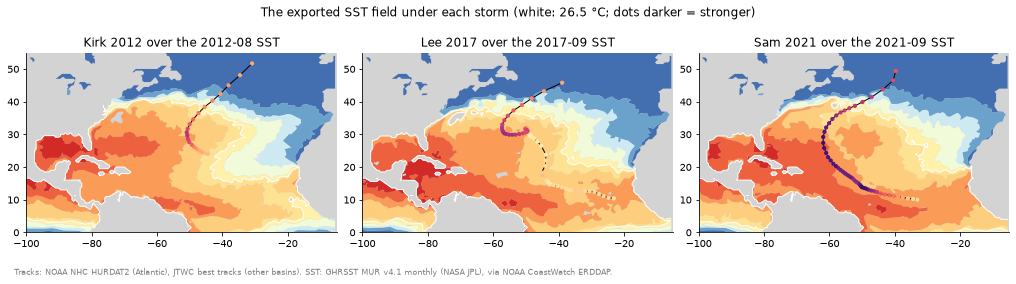

In [26]:
from shapely.geometry import LineString, MultiLineString, Polygon, mapping
from shapely import set_precision
from shapely.geometry.polygon import orient

FIELD_BOX = {"lat": (0, 55), "lon": (-100, -5)}
FIELD_EVERY = 2  # every 2nd grid point: 0.5°
FIELD_LEVELS = [22, 24, 25, 26, WARM_C, 27, 28, 29, 30]  # band edges (°C); the lowest and highest bands are open
FIELD_SIMPLIFY_DEG = 0.2
FIELD_DECIMALS = 1
FIELD_MIN_DEG2 = 0.5  # specks and holes smaller than two grid cells are left out


def rounded(o, decimals=FIELD_DECIMALS):
    if isinstance(o, float):
        return round(o, decimals)
    if isinstance(o, (list, tuple)):
        return [rounded(x, decimals) for x in o]
    if isinstance(o, dict):
        return {k: rounded(v, decimals) for k, v in o.items()}
    return o


def sst_field(month):
    """GeoJSON features of the month's SST in the Atlantic box: a (multi)polygon per band, and the 26.5 °C line."""
    rows = (GRID_LAT >= FIELD_BOX["lat"][0]) & (GRID_LAT <= FIELD_BOX["lat"][1])
    cols = (GRID_LON >= FIELD_BOX["lon"][0]) & (GRID_LON <= FIELD_BOX["lon"][1])
    sst = read_mur(month)[rows][:, cols][::FIELD_EVERY, ::FIELD_EVERY]
    lat, lon = GRID_LAT[rows][::FIELD_EVERY], GRID_LON[cols][::FIELD_EVERY]
    lowest, highest = FIELD_LEVELS[0] - 1, FIELD_LEVELS[-1] + 1
    edges = [lowest] + FIELD_LEVELS + [highest]
    fig, ax = plt.subplots()
    bands = ax.contourf(lon, lat, np.clip(sst, lowest + 0.01, highest - 0.01), levels=edges)
    features = []
    for k, path in enumerate(bands.get_paths()):
        geom = None
        for ring in path.to_polygons(closed_only=True):
            if len(ring) < 4:
                continue
            p = Polygon(ring).buffer(0)
            geom = p if geom is None else geom.symmetric_difference(p)
        if geom is None or geom.is_empty:
            continue
        props = {"month": str(month), "sst_from_c": edges[k] if k > 0 else None, "sst_to_c": edges[k + 1] if k + 1 < len(edges) - 1 else None}
        geom = set_precision(geom.simplify(FIELD_SIMPLIFY_DEG, preserve_topology=True), 10 ** -FIELD_DECIMALS)
        parts = []
        for p in getattr(geom, "geoms", [geom]):
            if p.geom_type != "Polygon" or p.area < FIELD_MIN_DEG2:
                continue
            p = Polygon(p.exterior, [h for h in p.interiors if Polygon(h).area >= FIELD_MIN_DEG2])
            parts.append(orient(p, sign=1.0))  # RFC 7946 winding: exterior rings anticlockwise, holes clockwise
        if not parts:
            continue
        geometry = mapping(parts[0]) if len(parts) == 1 else {"type": "MultiPolygon", "coordinates": [mapping(p)["coordinates"] for p in parts]}
        features.append({"type": "Feature", "properties": props, "geometry": geometry})
    line = ax.contour(lon, lat, np.nan_to_num(sst, nan=-5), levels=[WARM_C])
    segments = MultiLineString([LineString(s) for s in line.allsegs[0] if len(s) > 3]).simplify(FIELD_SIMPLIFY_DEG)
    features.append({"type": "Feature", "properties": {"month": str(month), "isotherm_c": WARM_C}, "geometry": mapping(segments)})
    plt.close(fig)
    return features


for sid, (file, _) in TRACK_FILES.items():
    months = sorted(set(lives[sid]["t"].dt.to_period("M")))
    collection = {"type": "FeatureCollection", "features": [f for m in months for f in sst_field(m)]}
    text = json.dumps(rounded(collection), separators=(",", ":"))
    (TRACKS_DIR / f"{file}_sst.geojson").write_text(text)
    print(f"{file}_sst.geojson: {', '.join(map(str, months))}, {len(collection['features'])} features, {len(text) / 1e3:.0f} KB")

fig, axes = plt.subplots(1, len(TRACK_FILES), figsize=(14, 3.6), layout="constrained")
cmap = plt.get_cmap("RdYlBu_r")
for ax, (sid, (file, title)) in zip(axes, TRACK_FILES.items()):
    d = lives[sid]
    month = str(d["t"].dt.to_period("M").mode()[0])
    for f in json.loads((TRACKS_DIR / f"{file}_sst.geojson").read_text())["features"]:
        p = f["properties"]
        if p["month"] != month:
            continue
        geoms = f["geometry"]["coordinates"] if f["geometry"]["type"].startswith("Multi") else [f["geometry"]["coordinates"]]
        if "isotherm_c" in p:
            for line in geoms:
                ax.plot(*np.array(line).T, color="white", linewidth=1)
            continue
        level = p["sst_from_c"] if p["sst_from_c"] is not None else FIELD_LEVELS[0] - 1
        for poly in geoms:
            ax.fill(*np.array(poly[0]).T, color=cmap((level - 20) / 11), linewidth=0)
            for hole in poly[1:]:
                ax.fill(*np.array(hole).T, color="lightgray", linewidth=0)
    ax.plot(d["lon"], d["lat"], color="black", linewidth=1)
    ax.scatter(d["lon"], d["lat"], c=d["wind_kt"], cmap="magma_r", vmin=20, vmax=160, s=10, zorder=3)
    ax.set(facecolor="lightgray", xlim=FIELD_BOX["lon"], ylim=FIELD_BOX["lat"], aspect="equal", title=f"{title} over the {month} SST")
fig.suptitle("The exported SST field under each storm (white: 26.5 °C; dots darker = stronger)")
source_note(fig, CREDIT)

In [27]:
PAGE_5097 = {"svsId": 5097, "svsUrl": "https://svs.gsfc.nasa.gov/5097/",
             "message": "Hurricanes tend to form over the warm tropical oceans where the SST is warmer than ~26.5 C (~80 F)"}
PAGE_5072 = {"svsId": 5072, "svsUrl": "https://svs.gsfc.nasa.gov/5072/",
             "message": "These simple visualizations are plots of time vs. wind speed for each tropical storm/hurricane of Atlantic Hurricane seasons from 1950 to the present. Horizontal lines indicate wind speed category thresholds."}
HURDAT2_SOURCE = {
    "source": "HURDAT2 Atlantic best track (NOAA National Hurricane Center)",
    "sourceUrl": "https://www.nhc.noaa.gov/data/#hurdat",
    "downloadUrl": HURDAT2_URL,
    "version": "hurdat2-1851-2025-092326 (revised 2026-09-23)",
    "downloaded": "2026-11-14",
    "license": "US government work, public domain",
    "credit": "Landsea, C. W. and J. L. Franklin, 2013: Atlantic Hurricane Database Uncertainty and Presentation of a New Database Format. Mon. Wea. Rev., 141, 3576-3592.",
}
MUR_SOURCE = {
    "source": "GHRSST Level 4 MUR Global Foundation SST Analysis v4.1, monthly mean (jplMURSST41mday)",
    "sourceUrl": "https://podaac.jpl.nasa.gov/dataset/MUR-JPL-L4-GLOB-v4.1",
    "downloadUrl": MUR_URL.format(y="<year>", m=0).replace("-00-16", "-<month>-16"),
    "version": "4.1",
    "doi": "https://doi.org/10.5067/GHGMR-4FJ04",
    "downloaded": "2026-11-14",
    "license": "Free to use and redistribute, not for legal use (ERDDAP license attribute)",
    "credit": "JPL MUR MEaSUREs Project. 2015. GHRSST Level 4 MUR Global Foundation Sea Surface Temperature Analysis (v4.1). PO.DAAC. Monthly mean served by NOAA CoastWatch ERDDAP.",
    "substitute": "The dataset 5097 cites, from another distributor: PO.DAAC's copy needs an Earthdata login and is about 400 MB a day; NOAA CoastWatch ERDDAP serves its monthly mean without one.",
}
NOTES = {
    "AL112012": "Grows over warm water and weakens as it moves north into cold water: the SST under it falls 7.7 °C in a day. No landfall.",
    "AL142017": "Drifts weak for nine days, falls apart and comes back, grows over warm water east of Bermuda and weakens as it races north-east into cold water: the SST under it falls 7.9 °C in a day. No landfall.",
    "AL182021": "Grows over warm water and weakens as it moves north over cooler water. No landfall.",
}
tracks_json = []
for sid, (file, title) in TRACK_FILES.items():
    d = lives[sid]
    tracks_json.append({
        "file": f"{file}.csv",
        "title": title,
        "pages": [PAGE_5097, PAGE_5072],
        "note": f"Ours: {NOTES[sid]} The whole life of the storm (section 12); SST is the monthly mean under its centre, empty over land. "
                f"The Atlantic's neutral SST, where storms neither strengthen nor weaken on average over the next 24 hours, is {NEUTRAL['Atlantic']:.1f} °C (section 5.1).",
        "sources": [HURDAT2_SOURCE, MUR_SOURCE],
        "visuals": [f"{file}_sst.geojson"],
        "units": {"wind_kt": "kt (1-minute sustained)", "pressure_hpa": "hPa", "sst_c": "°C", "lat": "°", "lon": "°"},
        "timeRange": [d["t"].iloc[0].strftime("%Y-%m-%dT%H:%MZ"), d["t"].iloc[-1].strftime("%Y-%m-%dT%H:%MZ")],
    })
(TRACKS_DIR / "tracks.json").write_text(json.dumps(tracks_json, indent=2, ensure_ascii=False) + "\n")
listed = {t["file"] for t in tracks_json} | {v for t in tracks_json for v in t["visuals"]}
on_disk = {p.name for p in TRACKS_DIR.iterdir() if p.name != "tracks.json"}
assert listed == on_disk, (listed ^ on_disk)
print(f"tracks.json lists every file in {TRACKS_DIR}: {sorted(on_disk)}")

tracks.json lists every file in ../data/hot_oceans/tracks: ['kirk_2012.csv', 'kirk_2012_sst.geojson', 'lee_2017.csv', 'lee_2017_sst.geojson', 'sam_2021.csv', 'sam_2021_sst.geojson']
